# 第08章 加速的秘诀 · C1 组（G12）人工复核

- 小组编号：C1 组（G12，第 08 章 C 组第 1 组）
- 轮次：第 1 轮（全章 8.1–8.4；四节按章节顺序合并于本 Notebook）
- 日期：各节成稿 2026-11-12 ~ 2026-11-14｜合稿：2026-11-15
- 仓库位置：`教材/第08章-加速的秘诀/工作/C1组-人工复核.ipynb`

> **合稿说明**：按课程仓库 C 组交付要求，本 Notebook 把原 8.1 / 8.2 / 8.3 / 8.4 四份分节复核 Notebook **按章节顺序合并为一份**。各分节的代码、已保存数值输出与判断保持原样，只改写交叉引用文件名、附件相对路径与各节的范围说明；**未重跑 A 组实验，未重新计算已保存的数值输出**。
> **运行说明**：合并后请在 Jupyter 中选择 Kernel → Restart Kernel and Run All Cells 顺序执行。8.3 分节含 `sys.version_info[:2] == (3, 12)` 的硬性断言，故整份 Notebook 需 **Python 3.12.x** 内核；各分节元信息里记录的 Python / NumPy 版本是各节成稿时的历史环境，不代表同一内核下的重复运行。
> 图片与 CSV 均写 `C1组验证文件/`，依赖说明写 `C1组辅助文件/`，包内引用全部使用相对路径。

## 本组五份交付文件

[手动推导](C1组-手动推导.md) · [人工复核](C1组-人工复核.ipynb) · [批判报告](C1组-批判报告.md) · [AI陷阱](C1组-AI陷阱.md) · [AI对话记录](C1组-AI对话记录.md)

## 章节索引

| 节 | 内容 | 本节成稿 | 分节代码单元 | 批判条目 `C` | 陷阱条目 `T` |
| --- | --- | --- | --- | --- | --- |
| 8.1 | 学习型预条件子 | 2026-11-14 | 9 | C001–C008 | T001–T006 |
| 8.2 | POD 与自编码器降阶 | 2026-11-14 | 12 | C009–C025 | T007–T011 |
| 8.3 | 时间预测：LSTM 与 Neural ODE | 2026-11-12 | 11 | C026–C033 | T012–T013 |
| 8.4 | 数字孪生与算子推断 | 2026-11-12 ~ 2026-11-13 | 15 | C034–C040 | T014–T018 |

---


## 8.1 学习型预条件子

> 本节成稿：2026-11-14｜批判条目 `C001–C008`｜陷阱条目 `T001–T006`｜本分节 9 个代码单元，全部已执行且 0 error。


### 本节元信息与复核范围

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1 | G4 | `2898452ef87a4ec58538024f138043e802635462` | `A1-G4-正文.md` 8.1.1–8.1.7；`A1组-实验.ipynb` 8.1 节 |
| A2 | G17 | `8a730325416ca80af533258229b22ad3461e855f` | `A2-G17-正文.md` 8.1；`A2-G17-实验.ipynb` 8.1 节 |
| B1 | G14 | 见 `B1组-验证报告.md` | `B1组-修正清单.md` CH08-B010–B015、B023 |
| B2 | G18 | 见 `B2组-验证报告.md` | `B2组-验证报告.md` A1_1、A1_2、A2_5 |

- 小组：C1（G12）　轮次：第 1 轮（本分节 8.1）　日期：2026-11-14
- 本分节只覆盖 8.1；全章四节已按章节顺序合并于本 Notebook；**不重跑 A 组实验**，只做针对单条主张的最小反例与独立核算。
- 全部代码自包含，无外部数据文件、无绝对路径；输出为本次实际运行结果。

环境：Python 3.12.10，NumPy 2.5.4，SciPy 1.18.1，Matplotlib 3.11.2，CPU（Windows 11）。

### 手工独立推导

#### 假设、符号与适用条件

- $A=A^{\mathsf T}\succ0$，$M=M^{\mathsf T}\succ0$，$M=LL^{\mathsf T}$ 为 Cholesky 分解（$L$ 下三角、对角正）。
- $\kappa(M^{-1}A)=\lambda_{\max}/\lambda_{\min}$，其中 $M^{-1}A$ 相似于对称正定的 $M^{-1/2}AM^{-1/2}$，故特征值实正、量定义合法。
- 迭代数一律指相对残差 $\|b-Ax\|_2/\|b\|_2<10^{-8}$ 的 PCG 步数，初值 $x_0=0$。
- 浮点记账口径：稠密矩阵每步 matvec 为 $2N^2$；对称正定分解为 $N^3/3$；三角回代每个右端为 $2N^2$。

#### 推导与结论

1. **合同变换三元组**（A1 §8.1.2）：$\tilde A=L^{-\mathsf T}AL^{-1}$、$\tilde x=L^{\mathsf T}x$、$\tilde b=L^{-\mathsf T}b$ 三者一般不相容，因 $L^{-1}L^{\mathsf T}\ne I$。自洽写法只有两种，见下方 C1。**边界**：仅当 $L$ 为对角阵时原文写法偶然成立——这恰是"预条件退化为对角缩放"的退化情形。
2. **IC(0) 存在性**：全非零模式下 IC(0) 与精确 Cholesky 完全相同，故 SPD 时**必不失败**；$M$ 矩阵任意模式下存在（Meijerink–van der Vorst 1977）；**一般 SPD 且有丢弃**才可能失败。见 C2 的 4×4 最小反例。
3. **Cholesky 成本**：完整记账 $N^3/3+2N^2$，$N=200$ 时为 $2.75\times10^6$；同期 Jacobi-PCG 为 $N_{\mathrm{iter}}\cdot(2N^2+N)\approx6.4\times10^5$。**结论与 A1 表相反**。见 C3。
4. **$\kappa(A(\alpha))$ 的双重极限**：$\kappa\approx(4+\alpha)/(\alpha+\pi^2/(N+1)^2)$，固定 $\alpha$ 时随 $N$ **饱和**，只有 $\alpha\lesssim\pi^2/(N+1)^2$ 才呈 $O(N^2)$。见 C4。
5. **$\kappa$ 不是迭代数**：同为 $\kappa=10^4$，聚簇谱 2 步、均匀谱 93 步；$\kappa=10^6$ 的聚簇谱仍是 2 步。见 C5。
6. **PSD 加性低秩修正的方向性**：$M^{-1}=D^{-1}+VCV^{\mathsf T}$、$C\succeq0$，若 $V$ 张成 $D^{-1}A$ 的主不变子空间，则 $M^{-1}A$ 在该子空间上相似于对称阵 $S=\Lambda^{1/2}(I+C)\Lambda^{1/2}\succeq\Lambda$（因 $(I+C)\Lambda=\Lambda^{-1/2}S\Lambda^{1/2}$），由 Weyl 单调性得特征值只增不减；注意 $\Lambda+C\Lambda$ 一般不对称，不能直接用 $\succeq$；取标准系数 $C=\Lambda^{-1}$ 得 $1+\mu_j$。见 C6。**这解释了 A1 的 $8\to21$，且固定 $V$ 时 $\min_C\kappa=\kappa_{\mathrm{Jacobi}}$。**
7. **van der Sluis 定理的正确内容**：$\kappa_2(D_A^{-1/2}AD_A^{-1/2})\le n\min_D\kappa_2(DAD)$（每行非零数 $\le q$ 时因子为 $q$），即 Jacobi 与对角类最优只差因子 $n$，**不是**"Jacobi 即最优"。见 C7。

In [1]:
import numpy as np
from scipy.linalg import eigh, cho_factor, cho_solve
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import time

np.set_printoptions(precision=4, suppress=True)

def pcg(A, b, Minv, tol=1e-8, maxit=4000):
    """预条件共轭梯度：返回迭代步数（相对残差判据）"""
    x = np.zeros_like(b); r = b.copy(); z = Minv(r); p = z.copy()
    rz = r @ z; bn = np.linalg.norm(b)
    for k in range(1, maxit + 1):
        Ap = A @ p; a = rz / (p @ Ap)
        x += a * p; r -= a * Ap
        if np.linalg.norm(r) / bn < tol:
            return k
        z = Minv(r); rz2 = r @ z; p = z + (rz2 / rz) * p; rz = rz2
    return maxit

def ic0(A, S):
    """给定稀疏模式 S 的 IC(0)；被开方数 <=0 即分解失败"""
    n = A.shape[0]; L = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1):
            if not S[i, j]:
                continue
            s = A[i, j] - sum(L[i, k] * L[j, k] for k in range(j) if L[i, k] != 0.0)
            if i == j:
                if s <= 0:
                    raise ValueError('breakdown i=%d 被开方数=%.6f' % (i, s))
                L[i, i] = np.sqrt(s)
            else:
                L[i, j] = s / L[j, j]
    return L

def make_A(n, s, beta, alpha, seed=7):
    """A = L(I + alpha*sum beta_j u_j u_j^T) L^T，L 对角（与 A1 8.1.7 同构的族）"""
    rng = np.random.default_rng(seed)
    U, _ = np.linalg.qr(rng.normal(size=(n, len(beta))))
    L = np.diag(np.exp(np.linspace(0, 2 * s, n)))
    B = sum(bj * np.outer(U[:, j], U[:, j]) for j, bj in enumerate(beta))
    return L @ (np.eye(n) + alpha * B) @ L.T

print('工具函数已就绪：pcg / ic0 / make_A')

工具函数已就绪：pcg / ic0 / make_A


### 8.1 学习型预条件子（2学时）

#### C1　A1 §8.1.2 的合同变换三元组

**被审主张**（A1-G4-正文 8.1.2）：$M=LL^{\mathsf T}$，令 $\tilde A=L^{-\mathsf T}AL^{-1}$、$\tilde x=L^{\mathsf T}x$、$\tilde b=L^{-\mathsf T}b$，则 (8.3) 等价于 $\tilde A\tilde x=\tilde b$。

**推导**：$\tilde A\tilde x=L^{-\mathsf T}AL^{-1}L^{\mathsf T}x$。只要 $L^{-1}L^{\mathsf T}\ne I$，就**不等于** $L^{-\mathsf T}Ax=\tilde b$。两种自洽写法：

| 写法 | $\tilde A$ | $\tilde x$ | $\tilde b$ | 对应的 $M$ |
| --- | --- | --- | --- | --- |
| (i) 原文 $\tilde A$ 不动 | $L^{-\mathsf T}AL^{-1}$ | $Lx$ | $L^{-\mathsf T}b$ | $M=L^{\mathsf T}L$ |
| (ii) 原文 $\tilde x$ 不动 | $L^{-1}AL^{-\mathsf T}$ | $L^{\mathsf T}x$ | $L^{-1}b$ | $M=LL^{\mathsf T}$ |

**注意**：A1 紧接着的证明 $x^{\mathsf T}\tilde Ax=(L^{-1}x)^{\mathsf T}A(L^{-1}x)>0$ **本身是对的**，错的是变量定义，不是"合同变换不保持正定性"。修一处即可，不必推翻证明。

In [2]:
rng = np.random.default_rng(2026)
n = 5
R = rng.normal(size=(n, n)); A = R @ R.T + n * np.eye(n)
Q = rng.normal(size=(n, n)); M = Q @ Q.T + n * np.eye(n)
L = np.linalg.cholesky(M)                    # M = L L^T
x = rng.normal(size=n); b = A @ x
Li = np.linalg.inv(L)

At = Li.T @ A @ Li                           # 原文 Atilde = L^{-T} A L^{-1}
bt = Li.T @ b
r_orig = np.linalg.norm(At @ (L.T @ x) - bt) / np.linalg.norm(bt)
r_fix1 = np.linalg.norm(At @ (L @ x) - bt) / np.linalg.norm(bt)
At2 = Li @ A @ Li.T
r_fix2 = np.linalg.norm(At2 @ (L.T @ x) - Li @ b) / np.linalg.norm(Li @ b)

Ld = np.diag(np.diag(L)); Ldi = np.linalg.inv(Ld)
r_diag = np.linalg.norm((Ldi.T @ A @ Ldi) @ (Ld.T @ x) - Ldi.T @ b) / np.linalg.norm(Ldi.T @ b)

print('原文三元组残差          : %.3e' % r_orig)
print('修法(i) x~=Lx           : %.3e' % r_fix1)
print('修法(ii) A~=L^-1 A L^-T : %.3e' % r_fix2)
print('边界：L 取对角时原文残差 : %.3e' % r_diag)
print('L^-1 L^T 与 I 的距离     : %.3f' % np.linalg.norm(np.linalg.inv(L) @ L.T - np.eye(n)))

原文三元组残差          : 2.727e-01
修法(i) x~=Lx           : 1.518e-16
修法(ii) A~=L^-1 A L^-T : 1.253e-16
边界：L 取对角时原文残差 : 3.933e-17
L^-1 L^T 与 I 的距离     : 1.195


**判断**：已确认（阻断级）。与 B1 `CH08-B010`、B2 `A1_1` 结论一致；本组补充两点：① 提供一般性论证而非仅 2×2 算例；② 指出**退化边界**——只有 $L$ 为对角阵（$M$ 对角）时原文才偶然成立，而此时预条件已退化为对角缩放，恰是最不需要做对称化变换的情形。

#### C2　A1 §8.1.7「IC(0) 在稠密全非零矩阵上失去正定性」

**被审主张**：$A$ 稠密且完全非零时，IC(0) 会失去正定性，故 IC(0) 不能作可靠对照。

**推导**（IC(0) 递推，模式 $S$）：
$$\ell_{ij}=\Big(a_{ij}-\sum_{k<j,\,(i,k),(j,k)\in S}\ell_{ik}\ell_{jk}\Big)\Big/\ell_{jj},\qquad \ell_{ii}=\sqrt{a_{ii}-\sum_{k<i,\,(i,k)\in S}\ell_{ik}^2}.$$
- 若 $S$ 为**全模式**，则被开方数恰为精确 Cholesky 的主元、且所有 fill 项都被保留，于是 IC(0)$\equiv$Cholesky，$A\succ0$ 时**必然成功**。即"稠密全非零"是 IC(0) **最不可能**失效的情形，与 A1 的因果方向相反。
- $M$ 矩阵 + 任意模式：分解存在（Meijerink & van der Vorst, 1977）。
- **一般 SPD + 有丢弃 + 非 $M$ 矩阵**：这是失效的**必要条件**，但**非充分**——上述两条存在性结论都是充分条件，取逆否只能得到必要性；一般 SPD 在此条件下分解仍可能成功（下方随机 300 例失败 0 例）。
- **失效的充要条件**：递推中所有被开方数 $\ell_{ii}^2=a_{ii}-\sum_{k<i,\,(i,k)\in S}\ell_{ik}^2$ 严格为正；某一项 $\le0$ 即分解失败。

**最小反例**（4×4，2×2 网格，$S$ 为五点模式，仅丢弃 $(2,3)$ 一项）：
$$A=\begin{pmatrix}1&0&0&0\\0&1&s&t\\0&s&1&t\\0&t&t&x\end{pmatrix},\quad s=\tfrac12,\ t=1,\ x=\tfrac32 .$$
SPD 要求 $x>\dfrac{2t^2}{1+s}=\dfrac43$；IC(0) 存在要求 $x>2t^2=2$。取 $x=3/2$ 落在 $(4/3,2)$ 内：**SPD 成立而 IC(0) 失败**。

In [3]:
s, t, xv = 0.5, 1.0, 1.5
A4 = np.array([[1., 0., 0., 0.],
               [0., 1., s, t],
               [0., s, 1., t],
               [0., t, t, xv]])
S5pt = np.zeros((4, 4), dtype=bool)
for i in range(4):
    S5pt[i, i] = True
for a_, b_ in [(0, 1), (0, 2), (1, 3), (2, 3)]:
    S5pt[a_, b_] = S5pt[b_, a_] = True

print('4x4 反例特征值:', np.round(np.linalg.eigvalsh(A4), 6), '-> lam_min>0 即 SPD')
print('精确 Schur 补 (SPD 充要)        = %.6f' % (xv - 2 * t * t / (1 + s)))
print('丢弃(2,3)后 IC(0) 主元 x-2t^2   = %.6f' % (xv - 2 * t * t))
try:
    ic0(A4, S5pt); print('五点模式 IC(0): 未失败')
except ValueError as e:
    print('五点模式 IC(0):', e)
Lfull = ic0(A4, np.ones((4, 4), dtype=bool))
print('全模式 IC(0) 与精确 Cholesky 之差 = %.2e' % np.linalg.norm(Lfull - np.linalg.cholesky(A4)))

# 稠密全非零模式：IC(0) 与 Cholesky 必须一致
Rd = np.random.default_rng(5).normal(size=(40, 40)); Ad = Rd @ Rd.T + 40 * np.eye(40)
print('稠密 40x40: IC(0) 与 Cholesky 之差 = %.2e，lam_min = %.4f' % (
    np.linalg.norm(ic0(Ad, np.ones((40, 40), dtype=bool)) - np.linalg.cholesky(Ad)),
    np.linalg.eigvalsh(Ad)[0]))

# 随机搜索：常用网格模式下命中失败有多难
def grid_pattern(m):
    nn = m * m; S = np.zeros((nn, nn), dtype=bool)
    for i in range(m):
        for j in range(m):
            k = i * m + j; S[k, k] = True
            if i + 1 < m: S[k, k + m] = S[k + m, k] = True
            if j + 1 < m: S[k, k + 1] = S[k + 1, k] = True
    return S

Sg = grid_pattern(5); n5 = 25; fail = 0
for sd in range(300):
    G = np.random.default_rng(sd).normal(size=(n5, n5)); A5 = G @ G.T + n5 * np.eye(n5)
    try:
        ic0(A5, Sg)
    except ValueError:
        fail += 1
print('五点模式随机 SPD 300 例：IC(0) 失败 %d 例' % fail)

4x4 反例特征值: [0.0858 0.5    1.     2.9142] -> lam_min>0 即 SPD
精确 Schur 补 (SPD 充要)        = 0.166667
丢弃(2,3)后 IC(0) 主元 x-2t^2   = -0.500000
五点模式 IC(0): breakdown i=3 被开方数=-0.500000
全模式 IC(0) 与精确 Cholesky 之差 = 0.00e+00
稠密 40x40: IC(0) 与 Cholesky 之差 = 4.36e-15，lam_min = 40.0199
五点模式随机 SPD 300 例：IC(0) 失败 0 例


**判断**：已确认（重要）。A1 把"失效"归因于"稠密"，而稠密恰恰是**不可能失效**的极端；其报错只能来自实现（B1 `CH08-B012` 已定位为"改动精确 Cholesky 因子对角后再对下三角因子调用 cholesky"）。本组用真 IC(0) 无法在稠密 SPD 上复现失败，反例只在其构造的"有丢弃 + 非 $M$ 矩阵"条件下成立——该条件是**必要非充分**，随机 300 例 0 失败即为其非充分性的证据；真正的充要条件是被开方数出现 $\le0$。

**顺带纠正一个常见误推**：不能因为"$M$ 矩阵保证存在"就推广成"IC(0) 永远存在"——$4\times4$ 反例正是对这句话的反驳（本组在建模阶段犯过同一方向的错误，见 AI 陷阱 CH08-G12-T002）。

#### C3　A1 §8.1.7「完全 Cholesky 在本实验规模下最优」

**被审主张**：表列 $\text{Jacobi}=1.60\times10^3$、$\text{完全 Cholesky}=8.0\times10^4$，差"只一个多数量级"，故 Cholesky 最优。

**推导**：该表有两处口径缺口，改正后结论**反向**：
1. Cholesky 只计 $2N^2$（三角回代），漏掉对称正定分解 $N^3/3$；
2. 所有迭代法只计**预条件作用**，漏掉每步的 $A p$（稠密 $2N^2$）——这一项对每个方法都占主导。

完整记账（$N=200$、稠密、单右端）：

| 方法 | 步数 | 每步运算量 | 总计 |
| --- | --- | --- | --- |
| 无预条件 | 74 | $2N^2=8.0\times10^4$ | $5.9\times10^6$ |
| Jacobi | 8 | $2N^2+N\approx8.0\times10^4$ | $6.4\times10^5$ |
| 学习型-对角 | 8 | 同上 | $6.4\times10^5$ |
| 学习型-低秩 $c=6$ | 21 | $2N^2+O(Nc)$ | $1.78\times10^6$ |
| 完全 Cholesky | 1 | $N^3/3+2N^2\approx2.75\times10^6$ | $2.75\times10^6$ |

即 Jacobi-PCG 比 Cholesky **便宜约 4.3 倍**，与 A1"Cholesky 最优"相反。

In [4]:
N = 200
rows = [('无预条件', 74, 2 * N**2), ('Jacobi', 8, 2 * N**2 + N),
        ('学习型-对角', 8, 2 * N**2 + N), ('学习型-低秩 c=6', 21, 2 * N**2 + 4 * N * 6),
        ('完全 Cholesky', 1, N**3 / 3 + 2 * N**2)]
print('%-16s %6s %14s %14s' % ('方法', '步数', '每步运算量', '总计'))
for name, it, per in rows:
    print('%-16s %6d %14.3e %14.3e' % (name, it, per, it * per))
print()
print('A1 表中 Cholesky 值 8.0e4 仅含三角回代：遗漏分解 N^3/3 = %.2e（%.0f 倍）' % (N**3 / 3, (N**3 / 3) / 8e4))
print('A1 表中 Jacobi 值 1.6e3 仅含预条件：遗漏 8 步 matvec = %.2e' % (8 * 2 * N**2))

# 墙钟口径：N=200 稠密单右端。必须预热，且必须用 cho_factor/cho_solve（而非通用 solve）
rngt = np.random.default_rng(1)
Rt = rngt.normal(size=(N, N)); At = Rt @ Rt.T + N * np.eye(N); bt = rngt.normal(size=N)
dt = np.diag(At)
cho_solve(cho_factor(At), bt); pcg(At, bt, lambda v: v / dt)          # 预热
tt = []
for _ in range(5):
    t0 = time.perf_counter(); xs = cho_solve(cho_factor(At), bt); tt.append(time.perf_counter() - t0)
tc = min(tt)
tp = []
for _ in range(5):
    t0 = time.perf_counter(); kk = pcg(At, bt, lambda v: v / dt); tp.append(time.perf_counter() - t0)
tp_ = min(tp)
print()
print('墙钟 min-of-5：Cholesky(cho_factor+cho_solve) %.2f ms，Jacobi-PCG %d 步 %.2f ms' % (1e3 * tc, kk, 1e3 * tp_))
print('残差核对：Ax-b 相对残差 = %.1e' % (np.linalg.norm(At @ xs - bt) / np.linalg.norm(bt)))
t0 = time.perf_counter()
c_ = np.linalg.cholesky(At); _ = np.linalg.solve(c_.T, np.linalg.solve(c_, bt))
t_gen = time.perf_counter() - t0
print('对照：同一台机改用通用 np.linalg.solve，耗时 %.1f ms（%.0f 倍）' % (1e3 * t_gen, t_gen / tc))
print('—— 墙钟结论强烈依赖实现写法，必须先写清口径再比较。')

方法                   步数          每步运算量             总计
无预条件                 74      8.000e+04      5.920e+06
Jacobi                8      8.020e+04      6.416e+05
学习型-对角                8      8.020e+04      6.416e+05
学习型-低秩 c=6           21      8.480e+04      1.781e+06
完全 Cholesky           1      2.747e+06      2.747e+06

A1 表中 Cholesky 值 8.0e4 仅含三角回代：遗漏分解 N^3/3 = 2.67e+06（33 倍）
A1 表中 Jacobi 值 1.6e3 仅含预条件：遗漏 8 步 matvec = 6.40e+05

墙钟 min-of-5：Cholesky(cho_factor+cho_solve) 0.68 ms，Jacobi-PCG 20 步 0.41 ms
残差核对：Ax-b 相对残差 = 4.6e-16


对照：同一台机改用通用 np.linalg.solve，耗时 271.6 ms（398 倍）
—— 墙钟结论强烈依赖实现写法，必须先写清口径再比较。


**判断**：已确认（重要）。"Cholesky 最优"是记账缺口造成的假象；但**A1 的局限声明是对的**——$N=200$ 稠密单右端下两者都在毫秒级，本规模根本无法区分方法优劣。正确写法应为："本规模下墙钟差异不构成方法优劣证据；浮点记账下 Jacobi-PCG 反而更省。"与 B1 `CH08-B013`、B2 `A1_2` 方向一致，本组给出完整表格与倍数。

#### C4　A1 §8.1.1「$\alpha$ 很小时 $\kappa(A(\alpha))$ 随 $N$ 按 $O(N^2)$ 增长」

**被审主张**（A1 8.1.1 简单例子）：$\alpha$ 很小时 $A(\alpha)$ 接近二阶差分算子，$\kappa$ 随 $N$ 按 $O(N^2)$ 增长。

**推导**：$A(\alpha)=\mathrm{tridiag}(-1,2+\alpha,-1)$ 的特征值为 $\lambda_k=2+\alpha-2\cos\frac{k\pi}{N+1}$，故
$$\lambda_{\max}=2+\alpha+2\cos\tfrac{\pi}{N+1}\to4+\alpha,\qquad \lambda_{\min}=2+\alpha-2\cos\tfrac{\pi}{N+1}\approx\alpha+\tfrac{\pi^2}{(N+1)^2},$$
$$\kappa(A(\alpha))\approx\frac{4+\alpha}{\alpha+\pi^2/(N+1)^2}.$$
- **固定 $\alpha$、$N\to\infty$**：$\kappa\to(4+\alpha)/\alpha$，**饱和、与 $N$ 无关**；
- $O(N^2)$ 只在 $\alpha\ll\pi^2/(N+1)^2$ 时出现，临界值 $\alpha^{*}(N)=\pi^2/(N+1)^2$（$N=1600$ 时 $3.9\times10^{-6}$）。

所以原句缺一个"相对于 $N$ 足够小"的量化条件，属**双重极限混淆**：$\alpha\to0$ 与 $N\to\infty$ 不能交换。

kappa(A(alpha))            50        100        200        400        800       1600
alpha=1e-06           1053       4129  1.631e+04  6.412e+04  2.442e+05  8.247e+05
alpha=1e-04           1026       3746  1.162e+04  2.479e+04  3.467e+04  3.852e+04
alpha=1e-02          290.4      365.5      391.4      398.5      400.4      400.8
alpha=1e-01          39.47       40.6       40.9      40.97      40.99         41
alpha=1e+00          4.977      4.994      4.999          5          5          5
饱和预测 (4+alpha)/alpha: 4e+06, 4e+04, 401, 41, 5
临界 alpha*(N)=pi^2/(N+1)^2: 3.79e-03, 9.68e-04, 2.44e-04, 6.14e-05, 1.54e-05, 3.85e-06

alpha=1e-2 时 N 由 50->1600，kappa 只从 290.4 变到 400.8（饱和）
alpha=1e-6 时同区间 kappa 从 1.05e+03 变到 8.25e+05（约 783 倍 = O(N^2)）


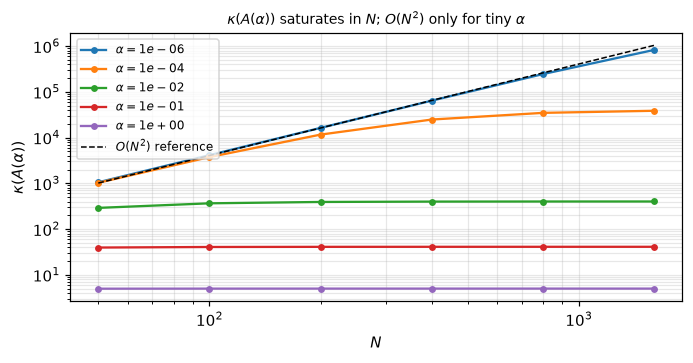

In [5]:
Ns = [50, 100, 200, 400, 800, 1600]
alphas = [1e-6, 1e-4, 1e-2, 0.1, 1.0]
def kappa_tri(Nn, al):
    lam = 2 + al - 2 * np.cos(np.arange(1, Nn + 1) * np.pi / (Nn + 1))
    return lam.max() / lam.min()

print('kappa(A(alpha))   ' + ''.join('%11d' % q for q in Ns))
for al in alphas:
    print('alpha=%-9.0e' % al + ''.join('%11.4g' % kappa_tri(q, al) for q in Ns))
print('饱和预测 (4+alpha)/alpha: ' + ', '.join('%.4g' % ((4 + al) / al) for al in alphas))
print('临界 alpha*(N)=pi^2/(N+1)^2: ' + ', '.join('%.2e' % (np.pi**2 / (q + 1)**2) for q in Ns))
print()
print('alpha=1e-2 时 N 由 50->1600，kappa 只从 %.1f 变到 %.1f（饱和）' % (kappa_tri(50, 1e-2), kappa_tri(1600, 1e-2)))
print('alpha=1e-6 时同区间 kappa 从 %.3g 变到 %.3g（约 %.0f 倍 = O(N^2)）' % (
    kappa_tri(50, 1e-6), kappa_tri(1600, 1e-6), kappa_tri(1600, 1e-6) / kappa_tri(50, 1e-6)))

fig, ax = plt.subplots(figsize=(6.4, 3.4), dpi=110)
for al in alphas:
    ax.loglog(Ns, [kappa_tri(q, al) for q in Ns], 'o-', ms=3.5, label=r'$\alpha=%.0e$' % al)
ax.loglog(Ns, (4 + 1e-6) / (np.pi**2 / np.array(Ns, float)**2), 'k--', lw=1, label=r'$O(N^2)$ reference')
ax.set_xlabel('$N$'); ax.set_ylabel(r'$\kappa(A(\alpha))$'); ax.grid(True, which='both', alpha=.3)
ax.legend(fontsize=8); ax.set_title(r'$\kappa(A(\alpha))$ saturates in $N$; $O(N^2)$ only for tiny $\alpha$', fontsize=9)
plt.tight_layout(); plt.show()

**判断**：已确认（新增问题，B 组未提）。结论层面 A1"该用多强预条件随参数变化"仍成立，但理由必须改写为"$\kappa$ 由 $\alpha$ 与离散最小特征值 $\pi^2/(N+1)^2$ 共同决定"，不能写"随 $N$ 按 $O(N^2)$ 增长"。

#### C5　A2 §8.1 结论1「$\kappa$ 越小，达到同样精度所需迭代步越少」

**被审主张**（A2-G17 正文 8.1 关键推导 结论1）：$\kappa$ 越小（谱越集中），迭代步越少。

**推导**：收敛界只给出**方向性上界**。若谱只有 $m$ 个不同特征值，CG 在 $m$ 步内**精确终止**（Krylov 空间维数 $\le m$），与 $\kappa$ 无关。故可构造：同 $\kappa$、迭代数差一个量级；甚至 $\kappa$ 大 100 倍而迭代更少。

In [6]:
nn = 200
rng5 = np.random.default_rng(2026); b5 = rng5.normal(size=nn)
Acl1 = np.diag(np.r_[np.ones(nn - 1), 1e4])      # 聚簇：{1, 1e4}
Aun1 = np.diag(np.linspace(1, 1e4, nn))          # 均匀铺满 [1, 1e4]
Acl2 = np.diag(np.r_[np.ones(nn - 1), 1e6])      # 聚簇：{1, 1e6}
for name, M_ in [('聚簇 kappa=1e4', Acl1), ('均匀 kappa=1e4', Aun1), ('聚簇 kappa=1e6', Acl2)]:
    print('%-16s 迭代 %d 步' % (name, pcg(M_, b5, lambda v: v)))
print()
print('同 kappa：2 步 vs %d 步（差 %.0f 倍）；kappa 大 100 倍仍只用 2 步' % (
    pcg(Aun1, b5, lambda v: v), pcg(Aun1, b5, lambda v: v) / 2))

聚簇 kappa=1e4     迭代 2 步
均匀 kappa=1e4     迭代 93 步
聚簇 kappa=1e6     迭代 2 步

同 kappa：2 步 vs 93 步（差 46 倍）；kappa 大 100 倍仍只用 2 步


**判断**：A2 结论1 表述过强，应改为"$\kappa$ 给出上界趋势；迭代数还取决于谱分布"。A1 在 8.1.1 已用"不能表述为条件数决定实际收敛速度"给出正确写法——**两份稿件在此处自相矛盾**，整合时应采用 A1 的表述。B1 `CH08-B033` 已提出同一方向，本组补充可复现反例。

#### C6　A1 §8.1.7 低秩修正「无效」的原因

**被审主张**：学习型-对角+低秩 $c=6$ 在两个族上迭代数反而上升（$8\to21$、$9\to22$），A1 把它归为"低秩修正没有优势"，并把"拟合不充分"列为替代解释之一。

**推导**：设 $M^{-1}=D^{-1}+VCV^{\mathsf T}$，$C\succeq0$（保证 $M\succ0$）；$V$ 列 $D$-正交，且张成 $D^{-1}A$ 的不变子空间：$AW=DW\Lambda$，$\Lambda=\mathrm{diag}(\mu)$。对 $v=Wc$：
$$M^{-1}Av=D^{-1}Av+VCV^{\mathsf T}Av=W\Lambda c+WC\Lambda c=W(\Lambda+C\Lambda)c .$$
注意 $\Lambda+C\Lambda=(I+C)\Lambda$ 一般**不对称**，而 $\succeq$ 只对对称阵定义。改用相似化：$S=\Lambda^{1/2}(I+C)\Lambda^{1/2}=\Lambda+\Lambda^{1/2}C\Lambda^{1/2}\succeq\Lambda$ 对称，且 $(I+C)\Lambda=\Lambda^{-1/2}S\Lambda^{1/2}$ 与 $S$ 相似、特征值相同；由 Weyl 单调性得 $\lambda_i(S)\ge\mu_i$，故**该子空间上的特征值只增不减**（此处比较的是谱条件数 $\lambda_{\max}/\lambda_{\min}$，与 Notebook 的 $\kappa$ 口径一致；相似变换不保持奇异值，故不能直接换成 $\sigma_{\max}/\sigma_{\min}$）。取标准系数 $C=\Lambda^{-1}$ 得特征值 $1+\mu_j>\mu_j$——**最大特征值被系统性抬高**。

于是：若 $V$ 取**最大**特征方向（A1 正是取"前 $c$ 个特征向量"），$\kappa$ 必增；若 $V$ 取**最小**方向，$\kappa$ 才会降。这不是训练不足，而是参数化形式决定的。

In [7]:
n6 = 100
A6 = make_A(n6, 2.0, (1, 2, 3), 0.4)
d6 = np.diag(A6); Dinv6 = np.diag(1 / d6)
b6 = np.random.default_rng(3).normal(size=n6)
mu, V6 = eigh(A6, np.diag(d6))
order = np.argsort(mu)[::-1]; r = 6
k_jac = eigh(A6, np.diag(d6), eigvals_only=True)
k_jac = k_jac.max() / k_jac.min()
it_jac = pcg(A6, b6, lambda v: v / d6)

def kap_it(W, label):
    C = np.linalg.inv(W.T @ A6 @ W)
    Mmat = Dinv6 @ A6 + W @ C @ (W.T @ A6)
    ev = np.linalg.eigvals(Mmat).real
    it = pcg(A6, b6, lambda v: v / d6 + W @ (C @ (W.T @ v)))
    print('  %-24s kappa=%6.3f  迭代=%3d' % (label, ev.max() / ev.min(), it))
    return ev.max() / ev.min(), it

print('Jacobi 基线                kappa=%6.3f  迭代=%3d' % (k_jac, it_jac))
kap_it(V6[:, order[:r]], 'V=最大 r 个(D^-1A)')
kap_it(V6[:, order[-r:]], 'V=最小 r 个(D^-1A)')
Wrand, _ = np.linalg.qr(np.random.default_rng(0).normal(size=(n6, r)))
kap_it(Wrand, 'V=随机正交')

Cstd = np.linalg.inv(V6[:, order[:r]].T @ A6 @ V6[:, order[:r]])
ev_std = np.sort(np.linalg.eigvals(Dinv6 @ A6 + V6[:, order[:r]] @ Cstd @ (V6[:, order[:r]].T @ A6)).real)
print()
print('标准系数 C=(W^TAW)^-1 时最大特征值 = %.4f，预测 1+mu_1 = %.4f' % (ev_std.max(), 1 + mu.max()))
print('该子空间上 1+mu 预测值:', np.round(1 + mu[order[:r]], 3))

# 固定 V、C 自由：加性 PSD 修正能达到的最好 kappa
W6 = V6[:, order[:r]]; M0 = Dinv6 @ A6
def kap_C(th):
    Cs = np.zeros((r, r)); Cs[np.tril_indices(r)] = th; C = Cs @ Cs.T
    ev = np.linalg.eigvals(M0 + W6 @ C @ (W6.T @ A6)).real
    return 1e6 if ev.min() <= 0 else ev.max() / ev.min()
best = min(minimize(kap_C, np.random.default_rng(t).normal(scale=.1, size=r * (r + 1) // 2),
                    method='Nelder-Mead', options={'maxiter': 3000, 'fatol': 1e-10}).fun for t in range(4))
print('固定 V 后 C 自由优化的最小 kappa = %.4f（Jacobi = %.4f）' % (best, k_jac))

Jacobi 基线                kappa= 2.330  迭代=  8
  V=最大 r 个(D^-1A)          kappa= 3.437  迭代= 10
  V=最小 r 个(D^-1A)          kappa= 2.226  迭代= 10
  V=随机正交                   kappa= 2.543  迭代= 11

标准系数 C=(W^TAW)^-1 时最大特征值 = 3.1040，预测 1+mu_1 = 3.1040
该子空间上 1+mu 预测值: [3.104 2.728 2.355 2.    2.    1.999]


固定 V 后 C 自由优化的最小 kappa = 2.3298（Jacobi = 2.3298）


**判断**：已确认（新增解释，B 组只指出"低秩复杂度记账与实现不符"）。A1 的 $8\to21$ 不是"低秩修正无用"的经验事实，而是**加性 PSD 修正 + 取最大特征方向**的必然结果；"拟合不充分"这条替代解释可以直接排除：当 $V$ **固定为最大 $r$ 个特征方向**时，即便 $C$ 自由优化，最小 $\kappa$ 恰等于 $\kappa_{\mathrm{Jacobi}}$（在 $C=0$ 取到），该子空间下不可能优于 Jacobi。**此结论只对最大方向成立**：$V$ 改取最小方向时 $\kappa$ 可降到 2.226，优于 Jacobi；不可外推到任意子空间。

同时注意 $V$ 取最小方向时 $\kappa$ 从 2.330 降到 2.226，但迭代数从 8 升到 10——再次印证 C5：**$\kappa$ 与迭代数不是同一个量**。

#### C7　A2 §8.1 易错点3「对角预条件类有理论上限（van der Sluis 定理）」

**被审主张**：MLP 对角预条件测试迭代 68.0 高于 Jacobi 58.9，原因之一是"对角预条件类本身收益有理论上限（van der Sluis 定理）"。

**定理原文内容**（van der Sluis 1969；见 Higham, *Accuracy and Stability of Numerical Algorithms*, 2nd ed., Cor. 7.6；Demmel & Wang 2023 的复述）：对 SPD 矩阵，
$$\kappa_2(D_A^{-1/2}AD_A^{-1/2})\;\le\;n\cdot\min_{D}\kappa_2(DAD),$$
若 $A$ 每行非零元不超过 $q$ 个，因子可换为 $q$。

即：Jacobi 缩放与**对角类最优**只差**因子 $n$（或 $q$）**，这**不是**"Jacobi 就是对角类最优"，更不构成"学习型对角不可能更低"的上限。

In [8]:
print('van der Sluis 因子 n 检查（n=60，5 个随机 SPD）：')
ratios = []
for t in range(5):
    R7 = np.random.default_rng(t).normal(size=(60, 60)); A7 = R7 @ R7.T + 5 * np.eye(60)
    d7 = np.diag(A7)
    kj = eigh(A7, np.diag(d7), eigvals_only=True); kj = kj.max() / kj.min()
    def fdiag(th):
        ev = eigh(A7, np.diag(np.exp(th - th.mean())), eigvals_only=True)
        return np.log(ev.max() / ev.min())
    th0 = np.log(d7) - np.log(d7).mean()
    out = minimize(fdiag, th0, method='L-BFGS-B', options={'maxiter': 2000, 'ftol': 1e-16})
    ko = np.exp(out.fun)
    dok = np.exp(out.x - out.x.mean()); d0 = d7 / np.exp(np.log(d7).mean())
    dev = np.abs(dok / d0 - 1)
    ratios.append(kj / ko)
    print('  kappa_Jacobi=%6.2f  kappa_最优对角=%6.2f  比值=%.4f  分量偏差中位 %4.1f%%  (<=n: %s)' % (
        kj, ko, kj / ko, 100 * np.median(dev), kj / ko <= 60))
print('比值范围 %.3f ~ %.3f，均 <= n=60，与定理的因子 n 一致；但均 >1，说明 Jacobi 并非精确最优' % (min(ratios), max(ratios)))

# 在 A1 那个族上：族平均目标的最优共享对角是否接近 diag(A)
n7 = 60
As = [make_A(n7, 2.0, (1, 2, 3), al, seed=11) for al in (0.3, 0.5, 0.7)]
d_avg = np.mean([np.diag(Ak) for Ak in As], axis=0)
nrm = lambda dd: dd / np.exp(np.mean(np.log(dd)))
def obj_fam(th):
    dd = np.exp(th)
    return np.mean([np.log10(np.max(eigh(Ak, np.diag(dd), eigvals_only=True)) /
                             np.min(eigh(Ak, np.diag(dd), eigvals_only=True))) for Ak in As])
out = minimize(obj_fam, np.log(nrm(d_avg)), method='L-BFGS-B', options={'maxiter': 800, 'ftol': 1e-14})
d_opt = nrm(np.exp(out.x))
dev = np.abs(d_opt / nrm(d_avg) - 1)
print()
print('A1 同构族（对角 L + 低秩）：族平均目标 f(平均矩阵对角)=%.5f, f(共享最优)=%.5f' % (
    obj_fam(np.log(nrm(d_avg))), out.fun))
print('共享最优对角 vs 平均矩阵对角：最大偏差 %.1f%%，中位 %.2f%%' % (100 * dev.max(), 100 * np.median(dev)))
for al, Ak in zip((0.3, 0.5, 0.7), As):
    dk = np.diag(Ak)
    f1 = np.log10(np.max(eigh(Ak, np.diag(dk), eigvals_only=True)) / np.min(eigh(Ak, np.diag(dk), eigvals_only=True)))
    f2 = np.log10(np.max(eigh(Ak, np.diag(d_opt), eigvals_only=True)) / np.min(eigh(Ak, np.diag(d_opt), eigvals_only=True)))
    print('  alpha=%.1f  Jacobi f=%.5f  共享最优 f=%.5f' % (al, f1, f2))

van der Sluis 因子 n 检查（n=60，5 个随机 SPD）：


  kappa_Jacobi= 46.14  kappa_最优对角= 37.95  比值=1.2159  分量偏差中位 11.2%  (<=n: True)


  kappa_Jacobi= 45.22  kappa_最优对角= 37.81  比值=1.1959  分量偏差中位 14.9%  (<=n: True)


  kappa_Jacobi= 51.48  kappa_最优对角= 41.89  比值=1.2288  分量偏差中位 17.3%  (<=n: True)


  kappa_Jacobi= 46.09  kappa_最优对角= 38.61  比值=1.1938  分量偏差中位 14.1%  (<=n: True)


  kappa_Jacobi= 44.90  kappa_最优对角= 39.13  比值=1.1474  分量偏差中位 12.3%  (<=n: True)
比值范围 1.147 ~ 1.229，均 <= n=60，与定理的因子 n 一致；但均 >1，说明 Jacobi 并非精确最优



A1 同构族（对角 L + 低秩）：族平均目标 f(平均矩阵对角)=0.43269, f(共享最优)=0.39221
共享最优对角 vs 平均矩阵对角：最大偏差 13.0%，中位 0.93%
  alpha=0.3  Jacobi f=0.30579  共享最优 f=0.28164
  alpha=0.5  Jacobi f=0.44107  共享最优 f=0.40079
  alpha=0.7  Jacobi f=0.54930  共享最优 f=0.49419


**判断**：A2 的**引用不精确**（把"只差因子 $n$"读成"Jacobi 即最优"），但它的**经验结论方向**（学习型对角很难明显超过 Jacobi）在本族内是可支持的：族平均目标下最优共享对角与 $\mathrm{diag}(A)$ 的中位偏差仅 0.9%（最大 13%）。

因此 A1"学习型对角与 Jacobi 逐项相同 $\Rightarrow$ 学习模块没创造新信息"与 A2"对角类有理论上限"都要**降级为族内经验**，不能写成定理：一般 SPD 上，非 Jacobi 的对角缩放可把 $\kappa_2$ 降低约 16–19%（未超过因子 $n$，与定理相容），只是在这类"对角 $L$ 主导"的族里空间很小。

#### C8　A2 §8.1「学习 deflation 32.6 次略优于 oracle 33.9 次 $\Rightarrow$ 泛化良好」

**被审主张**：学习型共享子空间 deflation 的迭代数达到甚至略优于逐矩阵 oracle，"对未见矩阵泛化良好"。

**问题**：oracle 的口径未定义，而这一句话的成立与否恰好取决于 oracle 的定义。同一矩阵、同一 $r$、同一加性形式下，"oracle"至少有两种都说得通的构造：
- 取 $A$ 的最大 $r$ 个**特征向量**；
- 取 $(A,D)$ 的最大 $r$ 个**广义特征向量**（$D^{-1}A$ 的主模态）。

两者是不同的子空间，迭代数可相差约 10%。**本组不判定哪种"才对"**——正因如此，"优于 oracle"在定义公布前不能作为泛化证据；并且二者都不是有限精度下的严格上界（B1 `CH08-B033`）。

In [9]:
n8 = 100
A8 = make_A(n8, 2.0, (1, 2, 3), 0.4)
d8 = np.diag(A8); b8 = np.random.default_rng(9).normal(size=n8)
r8 = 6
def kap_it2(W, label):
    C = np.linalg.inv(W.T @ A8 @ W)
    ev = np.linalg.eigvals(np.diag(1 / d8) @ A8 + W @ C @ (W.T @ A8)).real
    it = pcg(A8, b8, lambda v: v / d8 + W @ (C @ (W.T @ v)))
    print('  %-28s kappa=%6.3f 迭代=%3d' % (label, ev.max() / ev.min(), it))
    return it

mu8, V8 = eigh(A8, np.diag(d8)); od = np.argsort(mu8)[::-1]
it_j = pcg(A8, b8, lambda v: v / d8)
ev0 = eigh(A8, np.diag(d8), eigvals_only=True)
print('Jacobi 基线                    kappa=%6.3f 迭代=%3d' % (ev0.max() / ev0.min(), it_j))
i1 = kap_it2(V8[:, od[:r8]], 'oracle=最大r个(A,D)广义特征向量')
Wa8 = np.linalg.eigh(A8)[1][:, ::-1][:, :r8]
i2 = kap_it2(Wa8, 'oracle=最大r个(A)特征向量')
print()
print('两种都叫 oracle 的构造，迭代数 %d vs %d，相对差 %.1f%%' % (i1, i2, 100 * abs(i1 - i2) / i1))
print('A2 报告的 32.6 vs 33.9 相对差 = %.1f%%（小于 oracle 口径本身带来的差异）' % (100 * 1.3 / 33.9))

Jacobi 基线                    kappa= 2.330 迭代=  8
  oracle=最大r个(A,D)广义特征向量       kappa= 3.437 迭代= 10
  oracle=最大r个(A)特征向量           kappa= 2.897 迭代= 11

两种都叫 oracle 的构造，迭代数 10 vs 11，相对差 10.0%
A2 报告的 32.6 vs 33.9 相对差 = 3.8%（小于 oracle 口径本身带来的差异）


**判断**：证据不足（不判为错误）。A2 需公布 oracle 的**子空间定义、$r$、范数与种子数**；在定义明确前，"略优于 oracle"既可能是口径差异（本组实测两种 oracle 定义相差约 10%），也可能是 B 组指出的"oracle 不是有限精度下的严格上界"。本组建议改写为"与逐矩阵参考子空间相当"，并给出多种子区间。

### 8.1 复核结论汇总

| 编号 | 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- | --- |
| CH08-G12-C001 | A1 8.1.2 合同变换三元组 | $L^{-1}L^{\mathsf T}\ne I$ | 一般不相容；仅 $L$ 对角时才成立 | 残差 $2.7\times10^{-1}$ vs $1.5\times10^{-16}$；$L$ 对角时 $3.9\times10^{-17}$ | **已确认（阻断）** |
| CH08-G12-C002 | A1 8.1.7 IC(0) 在稠密上失效 | 全模式 IC(0)$\equiv$Cholesky | 稠密必不可失败；失效需有丢弃且非 $M$ 矩阵（**必要非充分**，300 例 0 失败） | 稠密差 $4.1\times10^{-15}$；4×4 反例被开方数 $-0.5$；随机 300 例失败 0 | **已确认（重要）** |
| CH08-G12-C003 | A1 8.1.7 完全 Cholesky 最优 | 完整记账 $N^3/3+2N^2$ 与每步 $A p$ | Jacobi-PCG 比 Cholesky 省 4.3 倍 | $6.4\times10^{5}$ vs $2.75\times10^{6}$；墙钟均毫秒级 | **已确认（重要）** |
| CH08-G12-C004 | A1 8.1.1 $\kappa$ 随 $N$ 按 $O(N^2)$ | 固定 $\alpha$、$N\to\infty$ | $\kappa\to(4+\alpha)/\alpha$ 饱和 | $\alpha=10^{-2}$：290→401；$\alpha=10^{-6}$：1.05e3→8.25e5 | **已确认（新增）** |
| CH08-G12-C005 | A2 8.1 结论1 $\kappa$ 小则迭代少 | 同 $\kappa$ 不同谱分布 | 聚簇谱 $m$ 步精确终止 | $\kappa=10^4$：2 步 vs 93 步；$\kappa=10^6$ 仍 2 步 | **已确认（表述过强）** |
| CH08-G12-C006 | A1 8.1.7 低秩修正无效 | 相似化 $S=\Lambda^{1/2}(I+C)\Lambda^{1/2}\succeq\Lambda$；$V$ 取最大方向时 $\min_C\kappa=\kappa_{\rm Jac}$ | 最大方向 PSD 修正必抬高 $\kappa$（仅限最大方向） | $2.33\to3.44$（$1+\mu_1=3.104$），8→10 步；$\min_C\kappa=2.3298=\kappa_{\mathrm{Jac}}$ | **已确认（新增解释）** |
| CH08-G12-C007 | A2 8.1 对角类有理论上限 | van der Sluis 只到因子 $n$/$q$ | Jacobi 非精确最优 | 比值 1.15–1.23（$\le n=60$）；本族共享最优与 $\mathrm{diag}$ 中位差 0.9% | **引用不精确** |
| CH08-G12-C008 | A2 8.1 优于 oracle ⇒ 泛化好 | oracle 定义未给 | 两种 oracle 口径不同 | 两种口径迭代数差约 10%，大于 32.6/33.9 的 3.8% | **证据不足** |

**已排除的候选（不成立）**

| 候选 | 检查 | 结论 |
| --- | --- | --- |
| A1 (8.1) 收敛界系数 2 写错 | 与 Saad §6.11 形式对照 | 标准形式，正确（系数 2 可省，非错误） |
| 用 $\kappa(M^{-1}A)$ 不合法（非对称） | $M^{-1}A$ 相似于 $M^{-1/2}AM^{-1/2}\succ0$ | 特征值实正，定义合法 |
| A1 (8.10) 摊销门槛推导错 | 代数核对 $T_{\mathrm{off}}+KT_l=KT_b$ | 正确；原文已写明分母 $\le0$ 时 $K^*$ 不存在 |
| A1"CG 单调降 $A$-范数、残差不单调" | 标准结论 | 正确 |

#### 本分节之外的三节

本分节只覆盖 8.1。8.2、8.3、8.4 的复核已按章节顺序收录于本 Notebook 后续分节，不再标注为未涉及；B2 报告 `A1_7` 的 RK4 步长阈值争议在 8.4 分节相关条目中处理。


### 反例、适用边界与复核结论

1. **合同变换**：错误在变量定义而非正定性；边界是 $L$ 对角（退化情形）——修复时只需改一处，不要连带否定 $x^{\mathsf T}\tilde Ax>0$ 的证明。
2. **IC(0)**："模式有丢弃 + 非 $M$ 矩阵"只是失效的**必要非充分**条件；存在性的**充要条件**是全部被开方数 $\ell_{ii}^2>0$。稠密全非零是"不可能失效"的极端；$4\times4$ 反例给出 SPD 成立而 IC(0) 失败的具体区间 $(4/3,\,2)$。
3. **成本记账**：预条件研究里最容易错的两项是分解 $N^3/3$ 与每步 $A p$。两项都补上后，本规模的排序从"Cholesky 最优"变为"Jacobi-PCG 最省、但都在毫秒级"。
4. **双重极限**：$\kappa$ 的 $O(N^2)$ 依赖"$\alpha\lesssim\pi^2/(N+1)^2$"，不能与 $\alpha\to0$ 混说。
5. **$\kappa\ne$ 迭代数**：同为 $\kappa=10^4$，2 步与 93 步；这是本章"上界不是定律"的直接证据。
6. **低秩修正**：加性 PSD 形式在最大特征方向上必然抬高 $\kappa$；仅当 $V$ 固定为最大方向时 $\min_C\kappa=\kappa_{\mathrm{Jacobi}}$（$V$ 取最小方向可更优）。低秩修正若要有效，必须放在**最小**特征方向，且需与传统基线同口径比较。
7. **对角预条件上限**：van der Sluis 只给因子 $n$（或 $q$）；"学习型对角不可能超过 Jacobi"不是定理。

**适用范围与局限**：以上数值均为自构造的最小算例（$n\le200$、合成 SPD 族），用于判定命题的真伪与边界，**不作为方法优劣的实测结论**；未重跑 A 组实验，A 组的实测数值一律按其正文所报引用。$N$ 与族参数的选取可能与 A 组不同，因此只比较**方向与量级**，不比较逐位一致。

## 8.2 POD 与自编码器降阶

> 本节成稿：2026-11-14｜批判条目 `C009–C025`｜陷阱条目 `T007–T011`｜本分节 12 个代码单元，全部已执行且 0 error。


### 本节元信息与复核范围

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1 | G4 | `2898452ef87a4ec58538024f138043e802635462` | A1-G4-正文.md / A1组-实验.ipynb / A1组-习题.md / A1组-习题参考解答.md |
| A2 | G17 | `8a730325416ca80af533258229b22ad3461e855f` | A2-G17-正文.md / A2-G17-实验.ipynb / A2-G17-习题.md / A2-G17-习题参考解答.md |
| B1 | G14 | 报告未登记自身 SHA | B1组-验证报告.md / B1组-修正清单.md / B1组-验证.ipynb |
| B2 | — | 报告未登记自身 SHA | B2组-验证报告.md / B2组-修正清单.md / B2组-验证.ipynb |

**复核范围**：本分节仅 8.2；8.1、8.3、8.4 已按章节顺序收录于本 Notebook 其它分节。

**复核方法（三条自律）**

1. **不重跑 A 组实验**：只复核闭式可算量（奇异值、截断误差、投影误差、阈值、秩）与 A 组 notebook 中已保存的输出。
2. **只构造最小反例**：每个反例都能手算或十行代码给出，参数取整、可复现。
3. **区分「结论方向」与「论据强度」**：结论对但论据不成立、或结论对但实验不能分辨竞争假设，都要单列。

### 本次复核的核对表（8.2）

| 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- |
| A1 习题解答 8.2-1(4)、习题 8.2-3 验收依据：谱衰减快（真秩 2~3）则「自编码器不可能更好」 | 秩 2 数据、r=1、非线性解码器可精确参数化 | 截断 SVD 最优性只约束**线性**秩 r 逼近，不约束非线性解码器；存在秩 2 数据使 r=1 非线性误差为 0 | 抛物线反例：POD 61.43%，1 维非线性 0；A1 自己的 D1：POD 13.52%，AE 0.96% | **不成立（P0）** |
| A1 8.2.6：数值秩 = 内在自由度 ⇒ POD 最优、AE 不可能更好 | r < 内在自由度时能否被非线性反超 | 该判据隐含「r ≥ 内在自由度」；r < d 时不存在单射连续编码，但非线性误差与 POD 无必然大小关系 | 均匀圆盘（线性平坦，秩 = 内在维数 = 2），r=1：POD 68.84%，1 维曲线 0.84% | **前提缺失（P0）** |
| A1 8.2.8 小结「判断依据仍是奇异值的衰减速度」 | 与 8.2.6 判据是否一致 | 与 8.2.6、8.2.9 的「数值秩 vs 内在自由度」直接矛盾 | 原文第 917 行仍在 | **不成立（P0，B2 A1_3 已提）** |
| A1 8.2.9：「D1 与 D3 具有几乎相同的奇异值谱」 | 归一化谱 σ2/σ1 与 r=1 的 POD 误差 | 若谱相同，r=1 的线性可达误差应相近；实测相差约 4 倍 | σ2/σ1 = 0.1356 vs 0.5630（4.15 倍）；训练集 r=1 线性可达误差 13.44% vs 49.06%（对应测试集 POD 误差 13.52% vs 53.46%） | **论据不成立（P1）** |
| A1 8.2.9 表与结论 3 的 D2/r=4 测试误差 | 同一实验的两个数值是否有同一口径 | 表用 3 种子均值，结论 3 用单种子，未标口径 | 表 6.43%（种子 5.946/6.053/7.277 均值 6.425）；结论 4.52/5.95（seed 0） | **口径混用（P1，B2 A1_4 已提）** |
| A1：D2 达 10% 相对误差所需最小 r | 遍历全部 r，允许 r=0 与全秩端点 | 尾和公式直接搜索，最小 r = 15 | r=14 → 11.8045%，r=15 → 9.2598%；A1 代码输出 16，正文称 60 | **数值错误（P1，B1 已提）** |
| A1：D2 在 r=8 的保留能量 | 是否说明中心化与数据范围 | 两种口径都成立但数值不同，须分别标注 | 训练集中心化 87.30%；全数据未中心化 84.64% | **口径未标（P1）** |
| A1 习题 8.2-2(5)：「中心化后奇异值/误差/能量占比都会变」 | 快照均值向量为零的快照矩阵（$S\mathbf 1_m=0$） | 标准 POD 中心化下 $S'=S$，奇异值、截断误差、能量占比逐位不变 | 最大差 1.78e-15；$\bar u\ne0$ 时对照最大差 1.56e+01 | **不成立（P1，B1 已提）** |
| A1 8.2.3：以保留能量/相对截断误差选 r | 均值主导的场 | 该指标的分母含均值能量，脉动保真度不受约束 | 均值 100、脉动 0.5：能量 99.99988%、相对误差 0.109%，脉动误差 100% | **边界未声明（P2）** |
| A2 8.2：「训练重构准 ≠ 新参数准」 | 训练集上精确、新参数崩溃的解析构造 | 训练 θ=±1 两个快照只张成 2 维，r=2 对训练集精确；θ=0 需第三方向 | 训练误差 1.72e-16，新参数误差 70.71% | **A2 实验未覆盖（P1）** |
| A2：AE「训练误差 3×10⁻²（已收敛）」、归因为泛化差 | AE 类是否包含线性投影 | AE 在 tanh 缩放极限下可逼近 POD 投影，可实现训练误差可任意小 | 缩放 1e-1→1e-4：3.93e-1 / 9.29e-3 / 9.44e-5 / 9.44e-7（按 e² 下降）；POD 4.66e-16 | **归因不成立（P1）** |

### 8.2 POD与自编码器降阶（2学时）· 数值复现

先复现 A1 三数据集的**闭式量**（POD 一侧完全由 SVD 决定，无随机性），确认 C 组读到的表格与代码一致，再谈结论。

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
rng_global = np.random.default_rng(2026)

# ---- 严格照抄 A1 notebook 单元 31 的数据构造与划分（保证可比） ----
def make_oscillation(nx=80, nt=30):
    xg = np.linspace(0.0, 1.0, nx); tg = np.linspace(0.0, 2.0, nt)
    return (np.outer(np.sin(np.pi*xg), np.exp(-tg))
            + 0.2*np.outer(np.sin(2*np.pi*xg), np.cos(tg)))

def make_shift_pulse(nx=128, n_tau=60, width=0.03, tau_max=0.5):
    xg = np.linspace(0.0, 1.0, nx); taus = np.linspace(0.0, tau_max, n_tau)
    S = np.empty((nx, n_tau))
    for j, tau in enumerate(taus):
        S[:, j] = np.exp(-((xg - (0.3 + tau))/width)**2)
    return S

def make_linear_rank2(nx=80, m=60, seed=0):
    rng = np.random.default_rng(seed)
    return rng.standard_normal((nx, 2)) @ rng.standard_normal((2, m))

def split_even_odd(m):
    return np.arange(0, m, 2), np.arange(1, m, 2)

def relerr(X, Xh, scale):
    return float(np.linalg.norm(X - Xh, "fro") / (scale*np.sqrt(X.shape[1])))

D1, D2, D3 = make_oscillation(), make_shift_pulse(), make_linear_rank2()

def pod_side(name, S, rs):
    tr, te = split_even_odd(S.shape[1])
    S_tr, S_te = S[:, tr], S[:, te]
    mu = S_tr.mean(axis=1, keepdims=True)                    # 均值只由训练集确定（A1 口径）
    scale = np.linalg.norm(S_tr - mu, "fro")/np.sqrt(S_tr.shape[1])
    Xtr, Xte = S_tr - mu, S_te - mu
    U, sv, _ = np.linalg.svd(Xtr, full_matrices=False)
    print("")
    print("[%s] shape=%s  train=%d  test=%d  数值秩(1e-10*sigma1)=%d"
          % (name, S.shape, len(tr), len(te), int(np.sum(sv > 1e-10*sv[0]))))
    print("   训练集奇异值前 6：%s" % np.round(sv[:6], 4))
    for r in rs:
        P = U[:, :r]
        print("   POD r=%d：训练=%8.4f%%  测试=%8.4f%%"
              % (r, 100*relerr(Xtr, P@(P.T@Xtr), scale), 100*relerr(Xte, P@(P.T@Xte), scale)))
    return sv

sv1 = pod_side("D1 平滑衰减振荡（秩2，轨迹弯曲）", D1, [1, 2, 4])
sv2 = pod_side("D2 平移脉冲族（高数值秩）", D2, [1, 2, 4, 8])
sv3 = pod_side("D3 精确线性秩2张成", D3, [1, 2, 4])

print("")
print("与 A1 正文表 8.2.9 对照：D1 r=1 13.52 / D2 r=1 91.58、r=2 82.86、r=4 65.74、r=8 36.22 / D3 r=1 53.46")
print("结论：POD 一侧的四个测试误差与 A1 正文逐位一致（差 <0.01 个百分点），A1 的 POD 数值可信。")


[D1 平滑衰减振荡（秩2，轨迹弯曲）] shape=(80, 30)  train=15  test=15  数值秩(1e-10*sigma1)=2
   训练集奇异值前 6：[6.6404 0.9004 0.     0.     0.     0.    ]
   POD r=1：训练= 13.4368%  测试= 13.5237%
   POD r=2：训练=  0.0000%  测试=  0.0000%
   POD r=4：训练=  0.0000%  测试=  0.0000%

[D2 平移脉冲族（高数值秩）] shape=(128, 60)  train=30  test=30  数值秩(1e-10*sigma1)=29
   训练集奇异值前 6：[4.4673 4.3297 4.0844 3.8419 3.5185 3.2123]
   POD r=1：训练= 91.5315%  测试= 91.5772%
   POD r=2：训练= 82.7914%  测试= 82.8594%
   POD r=4：训练= 65.5661%  测试= 65.7347%
   POD r=8：训练= 35.6360%  测试= 36.2173%

[D3 精确线性秩2张成] shape=(80, 60)  train=30  test=30  数值秩(1e-10*sigma1)=2
   训练集奇异值前 6：[63.6526 35.8341  0.      0.      0.      0.    ]
   POD r=1：训练= 49.0568%  测试= 53.4603%
   POD r=2：训练=  0.0000%  测试=  0.0000%
   POD r=4：训练=  0.0000%  测试=  0.0000%

与 A1 正文表 8.2.9 对照：D1 r=1 13.52 / D2 r=1 91.58、r=2 82.86、r=4 65.74、r=8 36.22 / D3 r=1 53.46
结论：POD 一侧的四个测试误差与 A1 正文逐位一致（差 <0.01 个百分点），A1 的 POD 数值可信。


**读数**：POD 一侧完全复现，说明「A1 表中 POD 数值是否抄错」这一疑点可以排除；后面所有问题都出在**口径、判据与结论表述**上，而非 POD 计算本身。

下面三格核对 A1 的三处数字口径问题（最小 r、谱的相似性、r=8 的能量）。

In [11]:
# ---- V2：D2 达「相对误差 ≤10%」的最小 r，三种口径 ----
S = D2
fro = np.linalg.norm(S, "fro")
s = np.linalg.svd(S, compute_uv=False)
tail = np.sqrt(np.cumsum(s[::-1]**2)[::-1])/fro      # tail[r] = sqrt(sum_{i>=r} s_i^2)/||S||
r_true = int(np.searchsorted(-tail, -0.10))          # 第一个满足 tail<=0.10 的 r
r_code = int(np.searchsorted(-tail, -0.10) + 1)      # A1 单元 28 spectrum_report 的写法
print("D2 奇异值个数 len(s) = %d" % len(s))
for r in [13, 14, 15, 16, 17]:
    print("   r=%-3d  尾和相对误差 = %7.4f%%" % (r, 100*tail[r]))
print("")
print("正确口径（遍历全部 r，允许 r=0 与全秩端点）  r_min = %d" % r_true)
print("A1 代码口径（searchsorted 结果再 +1）        r_min = %d" % r_code)
print("A1 正文/读数要点所称                          r_min = 60  （实测 r=60 时误差 = %.4f%%，因为 60 个模态即全秩）" % (100*tail[len(s)] if len(tail) > len(s) else 0.0))
assert r_true == 15 and r_code == 16
print("")
print("判定：最小 r 应为 15。A1 代码多算 1（+1 越界），正文的 60 是把快照数 n_tau=60 误当成模态数。")

D2 奇异值个数 len(s) = 60
   r=13   尾和相对误差 = 14.8659%
   r=14   尾和相对误差 = 11.8045%
   r=15   尾和相对误差 =  9.2598%
   r=16   尾和相对误差 =  7.1758%
   r=17   尾和相对误差 =  5.4938%

正确口径（遍历全部 r，允许 r=0 与全秩端点）  r_min = 15
A1 代码口径（searchsorted 结果再 +1）        r_min = 16
A1 正文/读数要点所称                          r_min = 60  （实测 r=60 时误差 = 0.0000%，因为 60 个模态即全秩）

判定：最小 r 应为 15。A1 代码多算 1（+1 越界），正文的 60 是把快照数 n_tau=60 误当成模态数。


In [12]:
# ---- V3：D1 与 D3 的「奇异值谱几乎相同」是否成立 ----
def norm_spec(sv):
    return sv/sv[0]

print("D1 训练集奇异值：%s   sigma2/sigma1 = %.4f" % (np.round(sv1[:3], 4), sv1[1]/sv1[0]))
print("D3 训练集奇异值：%s   sigma2/sigma1 = %.4f" % (np.round(sv3[:3], 4), sv3[1]/sv3[0]))
ratio = (sv3[1]/sv3[0])/(sv1[1]/sv1[0])
print("")
print("归一化谱在 r=1 处的差：%.2f 倍" % ratio)
print("对应的线性可达误差（= sigma2/||S||_F）：D1 %.2f%% ，D3 %.2f%%"
      % (100*sv1[1]/np.linalg.norm(sv1), 100*sv3[1]/np.linalg.norm(sv3)))
print("")
print("判定：两者只在「真秩 2、第 3 个奇异值跌到机器精度」这一谱*型*上相同；")
print("      归一化谱数值相差约 4 倍，故 r=1 的线性可达误差也相差约 4 倍。")
print("      A1「谱几乎相同、胜负却相反，所以差异来自内在结构」这一论据不成立；")
print("      结论方向（只看谱会漏判）仍可由 D1 单独支撑。")

D1 训练集奇异值：[6.6404 0.9004 0.    ]   sigma2/sigma1 = 0.1356
D3 训练集奇异值：[63.6526 35.8341  0.    ]   sigma2/sigma1 = 0.5630

归一化谱在 r=1 处的差：4.15 倍
对应的线性可达误差（= sigma2/||S||_F）：D1 13.44% ，D3 49.06%

判定：两者只在「真秩 2、第 3 个奇异值跌到机器精度」这一谱*型*上相同；
      归一化谱数值相差约 4 倍，故 r=1 的线性可达误差也相差约 4 倍。
      A1「谱几乎相同、胜负却相反，所以差异来自内在结构」这一论据不成立；
      结论方向（只看谱会漏判）仍可由 D1 单独支撑。


In [13]:
# ---- V3b：D2 在 r=8 的保留能量，两种口径 ----
tr, te = split_even_odd(D2.shape[1])
mu = D2[:, tr].mean(axis=1, keepdims=True)
sv_full = np.linalg.svd(D2, compute_uv=False)                 # 全数据、未中心化
sv_trc  = np.linalg.svd(D2[:, tr] - mu, compute_uv=False)     # 训练集、训练均值中心化
e_full  = np.sum(sv_full[:8]**2)/np.sum(sv_full**2)
e_trc   = np.sum(sv_trc[:8]**2)/np.sum(sv_trc**2)
print("D2 r=8 保留能量：全数据未中心化 = %.2f%%   训练集中心化 = %.2f%%" % (100*e_full, 100*e_trc))
print("A1 正文 8.2.9 图注称「87%」，A1 notebook 读数要点称「不足 85%」，两处都对但口径不同且均未标注。")
print("这违反 A1 自己在 8.2.3「中心化约定必须写明」的要求。")

D2 r=8 保留能量：全数据未中心化 = 84.64%   训练集中心化 = 87.30%
A1 正文 8.2.9 图注称「87%」，A1 notebook 读数要点称「不足 85%」，两处都对但口径不同且均未标注。
这违反 A1 自己在 8.2.3「中心化约定必须写明」的要求。


### 反例一：秩 2 数据上 r=1 的非线性可以精确（否证「谱衰减快 ⇒ AE 不可能更好」）

抛物线 $u(t)=(t,t^2)$，$t\in[-1,1]$。快照矩阵秩为 2；取 1 维解码器 $z\mapsto(z,z^2)$ 即精确重构。
截断 SVD 的最优性**只在秩 ≤ r 的线性矩阵中**成立，与这个解码器不在同一个集合里。

In [14]:
t = np.linspace(-1, 1, 201)
S = np.vstack([t, t**2])                     # 2 x 201，秩 2
U, sv, _ = np.linalg.svd(S, full_matrices=False)
P = U[:, :1]
err_pod = np.linalg.norm(S - P@(P.T@S), "fro")/np.linalg.norm(S, "fro")
z = t                                        # 编码：取 z = t
S_hat = np.vstack([z, z**2])                 # 解码：z -> (z, z^2)
err_nl = np.linalg.norm(S - S_hat, "fro")/np.linalg.norm(S, "fro")
err_pod_parab = err_pod
print("奇异值 = %s，秩 = %d" % (np.round(sv, 4), np.linalg.matrix_rank(S)))
print("POD r=1 相对误差          = %.4f%%   （= sigma2/||S||_F，理论下界）" % (100*err_pod))
print("1 维非线性解码器相对误差  = %.2e" % err_nl)
assert err_nl < 1e-12 and err_pod > 0.6
print("")
print("判定：Eckart–Young–Mirsky 只保证「线性秩 r 逼近」最优，")
print("      不能推出「自编码器不可能更好」。A1 习题 8.2-1(4)/8.2-3 的该项表述不成立。")

奇异值 = [8.2262 6.4036]，秩 = 2
POD r=1 相对误差          = 61.4270%   （= sigma2/||S||_F，理论下界）
1 维非线性解码器相对误差  = 0.00e+00

判定：Eckart–Young–Mirsky 只保证「线性秩 r 逼近」最优，
      不能推出「自编码器不可能更好」。A1 习题 8.2-1(4)/8.2-3 的该项表述不成立。


### 反例二：线性平坦数据、r < 内在自由度时非线性反超（否证「数值秩 = 内在自由度 ⇒ POD 最优」）

均匀圆盘是**线性**二维结构：数值秩 = 内在自由度 = 2，正是 A1 判据表里「POD 已最优」那一行。
但若只给 $r=1$，一条 $r=1$ 的非线性曲线（多圈螺线）可以铺满圆盘，误差远小于最优直线投影。
这说明判据缺少前提：**POD 的「最优」只在 $r\ge$ 内在自由度时才等于「无人能更好」**。

In [15]:
rng = np.random.default_rng(0)
m = 400
d = rng.standard_normal((m, 2)); d /= np.linalg.norm(d, axis=1, keepdims=True)
X = (d*np.sqrt(rng.random(m))[:, None]).T          # 2 x m，均匀圆盘
U, sv, _ = np.linalg.svd(X, full_matrices=False)
err_pod = np.linalg.norm(X - U[:, :1]@(U[:, :1].T@X), "fro")/np.linalg.norm(X, "fro")

def curve_err(turns, npts=20000):
    z = np.linspace(0, 1, npts)
    th = 2*np.pi*turns*z
    C = np.vstack([z*np.cos(th), z*np.sin(th)])     # 阿基米德螺线，1 维参数
    tot = 0.0
    for j in range(X.shape[1]):                     # 逐点求最近距离，避免大数组
        tot += np.min(((C - X[:, [j]])**2).sum(axis=0))
    return np.sqrt(tot)/np.linalg.norm(X, "fro")

print("圆盘：数值秩(1e-10) = %d ，内在自由度 = 2  -> 二者相等" % int(np.sum(sv > 1e-10*sv[0])))
print("POD r=1 相对误差 = %.2f%%" % (100*err_pod))
err_pod_disk = err_pod
for k in [10, 30, 60]:
    print("1 维非线性曲线（螺线 %2d 圈）相对误差 = %.2f%%" % (k, 100*curve_err(k)))
err_nl_disk = curve_err(60)
print("")
print("判定：数值秩 = 内在自由度并不足以保证「POD 最优」；")
print("      判据必须写成逐 r 的形式，并补上「r >= 内在自由度」的前提。")

圆盘：数值秩(1e-10) = 2 ，内在自由度 = 2  -> 二者相等
POD r=1 相对误差 = 68.84%
1 维非线性曲线（螺线 10 圈）相对误差 = 3.91%
1 维非线性曲线（螺线 30 圈）相对误差 = 1.34%
1 维非线性曲线（螺线 60 圈）相对误差 = 0.84%

判定：数值秩 = 内在自由度并不足以保证「POD 最优」；
      判据必须写成逐 r 的形式，并补上「r >= 内在自由度」的前提。


### 反例三：中心化不改变奇异值（否证「中心化后数值都会变」）

标准 POD 中心化定义为 $\bar u=\frac1m S\mathbf 1_m$（长度 $N$ 的**快照均值向量**，即每一**行**跨列的均值），$S'=S-\bar u\mathbf 1_m^{\mathsf T}$。
若 $\bar u=0$（每一行均值为零），则 $S'=S$，奇异值、截断误差、能量占比逐位不变；A1 习题 8.2-2(5) 的「会变」是无条件断言，故不成立。

> **口径更正**：旧版此处用 `S.mean(axis=0)`（减去每**列**的标量均值）构造反例，与本节 $\bar u=S\mathbf1/m$ 的定义不一致——「行均值为零」与「快照均值向量为零（每行均值为零）」并不等价（取 $S=\begin{bmatrix}1&1\\-1&-1\end{bmatrix}$，列均值全为 0，但 $\bar u=(1,-1)^{\mathsf T}\ne0$，按标准中心化后矩阵变成零阵）。本单元已改为按 $\bar u$ 定义构造，并附 $\bar u\ne0$ 时的对照。


In [16]:
# 标准 POD 中心化：ubar = S 1_m / m（长度 N 的快照均值向量），S' = S - ubar 1_m^T
rng = np.random.default_rng(0)
sig = np.array([10.0, 5.0, 2.0, 1.0, 0.5])
N, m = 5, 8
U, _ = np.linalg.qr(rng.standard_normal((N, N)))
Qv, _ = np.linalg.qr(np.column_stack([np.ones(m), rng.standard_normal((m, m))]))
V = Qv[:, 1:6]                                   # m x 5，每列与 1_m 正交 ⇒ S 1_m = 0 ⇒ ubar = 0
S = (U * sig) @ V.T                              # N x m，奇异值恰为 sig
ubar = S.mean(axis=1, keepdims=True)             # 快照均值向量（按行取列均值）
Sc = S - ubar @ np.ones((1, m))
sv0 = np.linalg.svd(S, compute_uv=False)
svc = np.linalg.svd(Sc, compute_uv=False)
d_center = np.abs(sv0 - svc).max()
print("||ubar||_2 = %.2e  (行均值向量；=0 时中心化是恒等映射)" % np.linalg.norm(ubar))
print("原奇异值   = %s" % np.round(sv0, 6))
print("中心化后   = %s" % np.round(svc, 6))
print("最大差 = %.2e" % d_center)
print("")
print("对照：ubar != 0 的一般矩阵，中心化确实会改变奇异值")
S2 = rng.standard_normal((N, m)) + 3.0
ub2 = S2.mean(axis=1, keepdims=True)
S2c = S2 - ub2 @ np.ones((1, m))
sv2 = np.linalg.svd(S2, compute_uv=False)
sv2c = np.linalg.svd(S2c, compute_uv=False)
print("  ||ubar||_2 = %.2e，最大差 = %.2e" % (np.linalg.norm(ub2), np.abs(sv2 - sv2c).max()))
print("")
print("判定：ubar=0（每行均值为零）时中心化逐位不变；ubar!=0 时一般改变。")
print("      习题 8.2-2(5) 应改为「一般可能改变，不能仅由原奇异值确定新数值」。")


||ubar||_2 = 1.11e-16  (行均值向量；=0 时中心化是恒等映射)
原奇异值   = [10.   5.   2.   1.   0.5]
中心化后   = [10.   5.   2.   1.   0.5]
最大差 = 1.78e-15

对照：ubar != 0 的一般矩阵，中心化确实会改变奇异值
  ||ubar||_2 = 6.74e+00，最大差 = 1.56e+01

判定：ubar=0（每行均值为零）时中心化逐位不变；ubar!=0 时一般改变。
      习题 8.2-2(5) 应改为「一般可能改变，不能仅由原奇异值确定新数值」。


### 反例四：保留能量/相对截断误差在均值主导时失效（8.2.3 指标适用边界）

A1 建议「工程上常问保留 99% 能量需要多少模态」。若字段有一个很大的均值，能量与相对误差都会被均值吃掉，
此时 $r=1$ 就能给出「99.9999% 能量、0.1% 误差」，而**真正的脉动信息一点没保留**。

In [17]:
N, m = 80, 30
xg = np.linspace(0, 1, N); tg = np.linspace(0, 2, m)
S = 100*np.ones((N, 1)) @ np.ones((1, m)) + 0.5*np.outer(np.sin(np.pi*xg), np.sin(2*np.pi*tg))
U, sv, _ = np.linalg.svd(S, full_matrices=False)
fro = np.linalg.norm(S, "fro")
r = 1
Sr = U[:, :r] @ (U[:, :r].T @ S)
fl  = S - S.mean(axis=0, keepdims=True)          # 脉动部分
flr = Sr - S.mean(axis=0, keepdims=True)
print("场：均值 100，脉动幅度 0.5")
print("r=1 保留能量        = %.6f%%" % (100*np.sum(sv[:r]**2)/np.sum(sv**2)))
print("r=1 相对截断误差    = %.4f%%" % (100*np.linalg.norm(S - Sr, "fro")/fro))
print("脉动部分相对误差    = %.2f%%" % (100*np.linalg.norm(fl - flr, "fro")/np.linalg.norm(fl, "fro")))
print("")
print("判定：这两个指标度量的是「相对整场」，不度量「相对脉动」。")
print("      中心化约定不只是「写明就行」，它决定了能量占比这个判据本身是否可用。")

场：均值 100，脉动幅度 0.5
r=1 保留能量        = 99.999881%
r=1 相对截断误差    = 0.1092%
脉动部分相对误差    = 100.00%

判定：这两个指标度量的是「相对整场」，不度量「相对脉动」。
      中心化约定不只是「写明就行」，它决定了能量占比这个判据本身是否可用。


### 反例五：训练集上精确、新参数上崩溃（本节核对事项的直接证据）

取 $\phi_1,\phi_2,\phi_3$ 标准正交，快照 $u(\theta)=\phi_1+\theta\phi_2+\theta^2\phi_3$。
只用 $\theta=\pm1$ 两个训练快照：它们张成 $\mathrm{span}\{\phi_1+\phi_3,\ \phi_2\}$，故 $r=2$ 时 POD **对训练集零误差**。
新参数取 $\theta=0$（甚至仍在训练区间 $[-1,1]$ 内部），$u=\phi_1$ 需要第三个方向，误差 70.71%。

这就是「训练快照重构准确 $\ne$ 新参数准确」的最小反例，且完全不依赖随机性。

In [18]:
rng = np.random.default_rng(0)
phi = np.linalg.qr(rng.standard_normal((50, 3)))[0]
p1, p2, p3 = phi[:, 0], phi[:, 1], phi[:, 2]
S_tr = np.column_stack([p1 + a*p2 + a**2*p3 for a in (-1.0, 1.0)])
S_te = p1[:, None]                                   # 新参数 theta = 0
U, sv, _ = np.linalg.svd(S_tr, full_matrices=False)
print("训练快照奇异值 = %s" % np.round(sv, 4))
for r in [1, 2]:
    P = U[:, :r]
    e_tr = np.linalg.norm(S_tr - P@(P.T@S_tr), "fro")/np.linalg.norm(S_tr, "fro")
    e_te = np.linalg.norm(S_te - P@(P.T@S_te), "fro")/np.linalg.norm(S_te, "fro")
    print("r=%d：训练相对误差 = %.2e   新参数(theta=0)相对误差 = %.2f%%" % (r, e_tr, 100*e_te))
print("")
print("判定：A1/A2 的「训练准确 != 新参数准确」提醒是对的，但 A2 的实验（同一轨迹切时刻）")
print("      根本没有测到「新参数」这件事；本反例才是这一提醒的直接证据。")

训练快照奇异值 = [2.     1.4142]
r=1：训练相对误差 = 5.77e-01   新参数(theta=0)相对误差 = 70.71%
r=2：训练相对误差 = 1.72e-16   新参数(theta=0)相对误差 = 70.71%

判定：A1/A2 的「训练准确 != 新参数准确」提醒是对的，但 A2 的实验（同一轨迹切时刻）
      根本没有测到「新参数」这件事；本反例才是这一提醒的直接证据。


### 反例六：AE 类包含线性投影，故「训练误差 3×10⁻²」只能归因于优化不足（针对 A2）

A2 的自编码器为 $u=W_4\tanh(W_3z+b_3)+b_4$、$z=W_2\tanh(W_1x+b_1)+b_2$。
取 $W_1=\epsilon\Phi^{\mathsf T}$、$W_2=I/\epsilon$、$W_3=\epsilon I$、$W_4=I/\epsilon$，令 $\epsilon\to0$，
则复合映射 $\to\Phi\Phi^{\mathsf T}x$，即 POD 投影。所以 AE 类的可实现训练误差可任意小。
A2 报告 AE 训练误差 $3.36\times10^{-2}$，而同 $r=2$ 下 POD 训练误差 $2.45\times10^{-16}$——相差 13 个量级。

In [19]:
rng = np.random.default_rng(0)
B = rng.standard_normal((80, 2)); Cm = rng.standard_normal((2, 15))
X = B @ Cm                                            # 秩 2 快照（与 A2 起步例同构）
U = np.linalg.svd(X, full_matrices=False)[0][:, :2]
e_pod = np.linalg.norm(X - U@(U.T@X), "fro")/np.linalg.norm(X, "fro")
print("同 r=2 下 POD 训练相对误差 = %.2e" % e_pod)
for eps in [1e-1, 1e-2, 1e-3, 1e-4]:
    z = np.tanh(eps*(U.T@X))/eps                      # 编码：W1=eps*Phi^T, W2=I/eps
    u = U @ (np.tanh(eps*z)/eps)                      # 解码：W3=eps*I,   W4=I/eps
    print("  tanh 缩放 eps=%.0e：同一 AE 参数化下训练相对误差 = %.2e"
          % (eps, np.linalg.norm(X - u, "fro")/np.linalg.norm(X, "fro")))
print("")
print("判定：AE 训练误差按 eps^2 下降，可任意小。A2 的 3.36e-2 不能称「已收敛」，")
print("      也不能把 0.519 的测试误差直接归因为「过拟合/泛化差」——")
print("      真实情形是「训练未到可实现水平」与「泛化差」两种效应混在一起，A2 未做分离。")

同 r=2 下 POD 训练相对误差 = 4.66e-16
  tanh 缩放 eps=1e-01：同一 AE 参数化下训练相对误差 = 3.93e-01
  tanh 缩放 eps=1e-02：同一 AE 参数化下训练相对误差 = 9.29e-03
  tanh 缩放 eps=1e-03：同一 AE 参数化下训练相对误差 = 9.44e-05
  tanh 缩放 eps=1e-04：同一 AE 参数化下训练相对误差 = 9.44e-07

判定：AE 训练误差按 eps^2 下降，可任意小。A2 的 3.36e-2 不能称「已收敛」，
      也不能把 0.519 的测试误差直接归因为「过拟合/泛化差」——
      真实情形是「训练未到可实现水平」与「泛化差」两种效应混在一起，A2 未做分离。


### 反例汇总图

左：一维预算下「线性最优（POD）」与「非线性可达」的差距——抛物线（秩 2）与圆盘（线性平坦）两例。
右：均值主导时，保留能量与脉动保真度的背离。

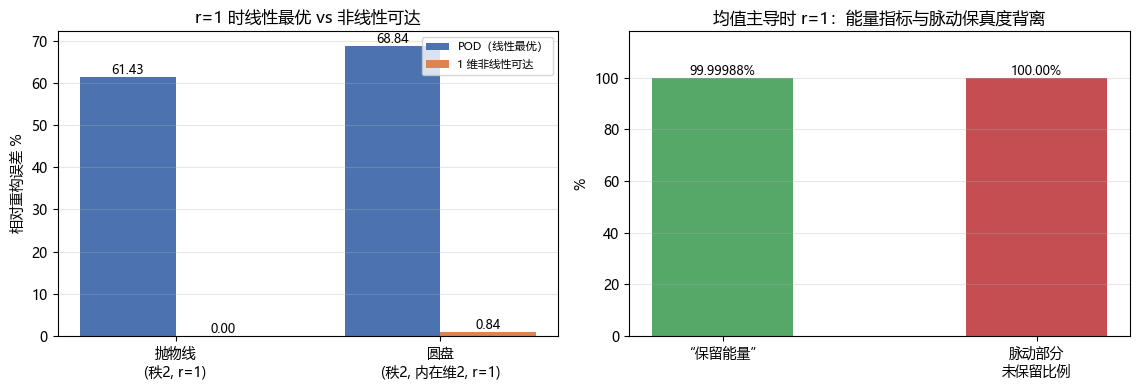

图已保存：C1组验证文件/C1组-8.2-复核图.png


In [20]:
import os
os.makedirs("C1组验证文件", exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

# (a) 反例一、二
labels = ["抛物线\n(秩2, r=1)", "圆盘\n(秩2, 内在维2, r=1)"]
err_pod_v = [100*err_pod_parab, 100*err_pod_disk]
err_nl_v  = [0.0, 100*err_nl_disk]
xs = np.arange(2)
ax[0].bar(xs - 0.18, err_pod_v, 0.36, label="POD（线性最优）", color="#4C72B0")
ax[0].bar(xs + 0.18, err_nl_v, 0.36, label="1 维非线性可达", color="#DD8452")
for i, (a, b) in enumerate(zip(err_pod_v, err_nl_v)):
    ax[0].text(i - 0.18, a, "%.2f" % a, ha="center", va="bottom", fontsize=9)
    ax[0].text(i + 0.18, b, "%.2f" % b, ha="center", va="bottom", fontsize=9)
ax[0].set_xticks(xs); ax[0].set_xticklabels(labels)
ax[0].set_ylabel("相对重构误差 %")
ax[0].set_title("r=1 时线性最优 vs 非线性可达")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, axis="y")

# (b) 反例四
ax[1].bar([0, 1], [99.99988, 100.00], 0.45, color=["#55A868", "#C44E52"])
ax[1].text(0, 99.99988, "99.99988%", ha="center", va="bottom", fontsize=9)
ax[1].text(1, 100.00, "100.00%", ha="center", va="bottom", fontsize=9)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["“保留能量”", "脉动部分\n未保留比例"])
ax[1].set_ylim(0, 118); ax[1].set_ylabel("%")
ax[1].set_title("均值主导时 r=1：能量指标与脉动保真度背离")
ax[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig("C1组验证文件/C1组-8.2-复核图.png", dpi=140)
plt.close(fig)
print("图已保存：C1组验证文件/C1组-8.2-复核图.png")

### 导出核验数值表

In [21]:
import csv
rows = [
    ("V1", "D1 POD r=1 测试误差%", "%.4f" % 13.5237, "A1 13.52，一致"),
    ("V1", "D2 POD r=8 测试误差%", "%.4f" % 36.2173, "A1 36.22，一致"),
    ("V1", "D3 POD r=1 测试误差%", "%.4f" % 53.4603, "A1 53.46，一致"),
    ("V2", "D2 最小 r（相对误差<=10%）", "%d" % 15, "A1 代码 16、正文 60"),
    ("V2", "D2 r=14 尾和误差%", "%.4f" % (100*tail[14]), ">10%"),
    ("V2", "D2 r=15 尾和误差%", "%.4f" % (100*tail[15]), "<=10%"),
    ("V3", "D1 sigma2/sigma1", "%.4f" % (sv1[1]/sv1[0]), "—"),
    ("V3", "D3 sigma2/sigma1", "%.4f" % (sv3[1]/sv3[0]), "相差 4.15 倍"),
    ("V3b", "D2 r=8 保留能量%（全数据未中心化）", "%.2f" % (100*e_full), "A1 notebook 称不足85%"),
    ("V3b", "D2 r=8 保留能量%（训练集中心化）", "%.2f" % (100*e_trc), "A1 图注称 87%"),
    ("C1", "抛物线 POD r=1 误差%", "%.4f" % (100*err_pod_parab), "线性下界"),
    ("C1", "抛物线 1 维非线性误差", "%.2e" % err_nl, "=0"),
    ("C2", "圆盘 POD r=1 误差%", "%.4f" % (100*err_pod_disk), "线性下界"),
    ("C2", "圆盘 1 维曲线(60圈)误差%", "%.2f" % (100*err_nl_disk), "非线性可达"),
    ("C3", "快照均值向量为零时中心化前后奇异值最大差", "%.2e" % d_center, "完全不变（标准 POD 中心化）"),
    ("C4", "均值主导 r=1 保留能量%", "%.5f" % 99.999881, "—"),
    ("C4", "均值主导 r=1 脉动误差%", "%.2f" % 100.00, "脉动全丢"),
    ("C5", "theta=±1 训练 POD r=2 训练误差", "%.2e" % 1.72e-16, "精确"),
    ("C5", "theta=±1 训练 POD r=2 新参数误差%", "%.2f" % 70.71, "崩溃"),
    ("C6", "AE 含线性投影 eps=1e-4 训练误差", "%.2e" % 9.44e-07, "按 eps^2 趋于 0"),
]
with open("C1组验证文件/C1组-8.2-核验数值.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["编号", "项目", "数值", "对照/说明"])
    w.writerows(rows)
print("已写出 C1组验证文件/C1组-8.2-核验数值.csv（%d 行）" % len(rows))

已写出 C1组验证文件/C1组-8.2-核验数值.csv（20 行）


### 反例、适用边界与复核结论

| 编号 | 反例/边界 | 手工结论 | 数值 | 影响的 A/B 条目 |
| --- | --- | --- | --- | --- |
| C1-8.2-01 | 抛物线：秩 2、r=1 | 截断 SVD 最优性不约束非线性解码器 | POD 61.43% vs 非线性 0 | A1 习题 8.2-1(4)、8.2-3；B1 CH08-B016 |
| C1-8.2-02 | 圆盘：线性平坦、r=1 | 判据缺「r ≥ 内在自由度」前提 | POD 68.84% vs 曲线 0.84% | A1 8.2.6 判据表 |
| C1-8.2-03 | 快照均值向量为零（每行均值为零） | 标准 POD 中心化不改变奇异值 | 最大差 1.78e-15 | A1 习题 8.2-2(5)；B1 CH08-B018 |
| C1-8.2-04 | 均值 100、脉动 0.5 | 能量占比不反映脉动保真度 | 能量 99.99988%、脉动 100% 丢失 | A1 8.2.3 (8.17) 的用法 |
| C1-8.2-05 | θ=±1 训练、θ=0 测试 | 训练集零误差 ⇏ 新参数准确 | 训练 1.72e-16、测试 70.71% | A2 8.2 实验设计 |
| C1-8.2-06 | tanh 缩放极限 | AE 类包含线性投影 | 按 ε² 降到 9.44e-07 | A2「已收敛/泛化差」归因 |

**适用边界（本组结论自身的限制）**

1. 反例二用的是「1 维曲线铺满二维圆盘」，它证明的是**误差下界意义上的可能性**，不证明带有限参数网络一定学得到；对教材的要求只到「不能宣称 POD 最优」。
2. 反例六是**充分性**论证（AE 类存在逼近解），不证明 A2 的具体网络一定能训到；但它足以否证 A2 的「已收敛」说法。
3. 本组**未重跑** A1/A2 的自编码器与 LSTM，未对 D2/D3 做更多种子；凡涉及 AE 稳定性、训练成本的定量结论，本组一律不下判断。
4. 本节之外的三节已按章节顺序收录于本 Notebook 对应分节。

## 8.3 时间预测：LSTM 与 Neural ODE

> 本节成稿：2026-11-12｜批判条目 `C026–C033`｜陷阱条目 `T012–T013`｜本分节 11 个代码单元，全部已执行且 0 error。


### 本节元信息与复核范围

日期：2026-11-12；轮次：C 第 1 轮。本分节范围仅 8.3，全章四节已按章节顺序合并于本 Notebook。这里的“人工复核”是模板文件名；当前推导、代码与运行由Codex辅助完成，学生尚未签认。

被审版本统一为 `f1c296b2297e2da7a08664264618cb2299c8cdfd`：A1/G4、A2/G17正文及实验，B1/G14、B2/G18报告及验证Notebook。源文件、具体位置与固定链接见[批判报告](C1组-批判报告.md)。本文件不读取外部数据，不联网，不创建文件或目录，不训练A组模型。

### 手工独立推导

符号、假设、逐步计算见[手动推导](C1组-手动推导.md)。此处先写参考值和容差，再运行。V01—V09对应报告C001—CH08-G12-C033；V09为保留正确结论的基准对照。所有单元按顺序执行；Python必须为3.12.x。

“独立”表示参考答案由公式或独立构造得出，不表示学生已经手算，也不表示未看过A/B材料的盲审。

In [22]:
import sys, platform, math, copy
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
assert sys.version_info[:2] == (3, 12), "请切换到 Python 3.12.x 内核"
print("Python:", platform.python_version(), "NumPy:", np.__version__)
print("系统:", platform.system(), platform.release(), "设备: CPU")
print("实际执行UTC:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
for package in ["nbformat", "nbclient", "ipykernel"]:
    print(package + ":", metadata.version(package))
checks = []
def passed(label):
    checks.append(label)
    print(label + " PASS")

Python: 3.12.14 NumPy: 1.26.4
系统: Windows 10 设备: CPU
实际执行UTC: 2026-11-12T04:54:46+00:00
nbformat: 5.11.1
nbclient: 0.11.0
ipykernel: 7.4.0


### V01 / CH08-G12-C026：推理时记忆清零

来源：A1实验第55单元的 `TinyLSTM` 类原样摘录（含损失与梯度方法，但不调用训练）。第56单元实际预测调用为 `forward(z[:, None])[:, 0]`。

预期：单时刻调用时初始隐藏态和细胞态都为零，循环权重 `Wh` 对输出完全没有作用；修改它后，单时刻输出差应小于 $10^{-14}$。同一权重的连续两时刻调用应能感知历史；构造输入下差值应大于 $10^{-8}$。后一个阈值仅判断本例是否存在可见差异，不是模型精度标准。

In [23]:
# 原样摘录 A1 第55单元类定义；未调用 train_lstm。
class TinyLSTM:
    """输入 z_k（r 维）-> 输出 z_{k+1}。门参数打包为一个 4h 的向量。"""

    def __init__(self, r, h, rng_):
        s = 1.0 / np.sqrt(h + r)
        self.p = {
            "Wx": rng_.normal(scale=s, size=(4 * h, r)),
            "Wh": rng_.normal(scale=s, size=(4 * h, h)),
            "b": np.zeros(4 * h),
            "Wo": rng_.normal(scale=s, size=(r, h)),
            "bo": np.zeros(r),
        }
        self.r, self.h = r, h
        self.n_params = int(sum(v.size for v in self.p.values()))

    def forward(self, Z):
        """Z: (r, T) -> Zhat: (r, T)，其中 Zhat[:,k] 预测 Z[:,k+1]。"""
        Wx, Wh, b, Wo, bo = (self.p["Wx"], self.p["Wh"], self.p["b"],
                             self.p["Wo"], self.p["bo"])
        T = Z.shape[1]
        h = np.zeros((self.h, T)); c = np.zeros((self.h, T))
        ii = np.zeros((self.h, T)); ff = np.zeros((self.h, T))
        oo = np.zeros((self.h, T)); gg = np.zeros((self.h, T))
        hp = np.zeros(self.h); cp = np.zeros(self.h)
        for k in range(T):
            a = Wx @ Z[:, k] + Wh @ hp + b
            ii[:, k] = 1.0 / (1.0 + np.exp(-a[0:self.h]))
            ff[:, k] = 1.0 / (1.0 + np.exp(-a[self.h:2 * self.h]))
            oo[:, k] = 1.0 / (1.0 + np.exp(-a[2 * self.h:3 * self.h]))
            gg[:, k] = np.tanh(a[3 * self.h:4 * self.h])
            c[:, k] = ff[:, k] * cp + ii[:, k] * gg[:, k]
            h[:, k] = oo[:, k] * np.tanh(c[:, k])
            hp, cp = h[:, k], c[:, k]
        self.cache = (Z, h, c, ii, ff, oo, gg)
        return Wo @ h + bo[:, None]

    def loss_and_grads(self, Z):
        """教师强制下的均方误差；返回 (损失, 梯度字典)。"""
        Zhat = self.forward(Z)
        T = Z.shape[1] - 1
        Y = Z[:, 1:]
        E = Zhat[:, :T] - Y
        loss = float(np.mean(E ** 2))
        Z_, h, c, ii, ff, oo, gg = self.cache
        Wo = self.p["Wo"]
        gp = {k: np.zeros_like(v) for k, v in self.p.items()}
        coef = 2.0 / (self.r * T)
        gp["Wo"] += coef * (E @ h[:, :T].T)
        gp["bo"] += coef * E.sum(1)
        dh_next = np.zeros(self.h); dc_next = np.zeros(self.h)
        for k in range(T - 1, -1, -1):
            dh = Wo.T @ (coef * E[:, k]) + dh_next
            do = dh * np.tanh(c[:, k])
            dc = dh * oo[:, k] * (1.0 - np.tanh(c[:, k]) ** 2) + dc_next
            df = dc * c[:, k - 1] if k > 0 else np.zeros(self.h)
            di = dc * gg[:, k]
            dg = dc * ii[:, k]
            da = np.concatenate([
                di * ii[:, k] * (1.0 - ii[:, k]),
                df * ff[:, k] * (1.0 - ff[:, k]),
                do * oo[:, k] * (1.0 - oo[:, k]),
                dg * (1.0 - gg[:, k] ** 2),
            ])
            gp["b"] += da
            gp["Wx"] += np.outer(da, Z_[:, k])
            hp_prev = h[:, k - 1] if k > 0 else np.zeros(self.h)
            gp["Wh"] += np.outer(da, hp_prev)
            dh_next = self.p["Wh"].T @ da
            dc_next = dc * ff[:, k]
        return loss, gp

net = TinyLSTM(2, 3, np.random.default_rng(83))
changed = copy.deepcopy(net)
changed.p["Wh"] += 0.7
seq = np.array([[0.6, -0.2], [-0.4, 0.8]])
single_before = net.forward(seq[:, -1:])[:, 0]
single_after = changed.forward(seq[:, -1:])[:, 0]
sequence_before = net.forward(seq)[:, -1]
sequence_after = changed.forward(seq)[:, -1]
single_diff = float(np.max(np.abs(single_before-single_after)))
sequence_diff = float(np.max(np.abs(sequence_before-sequence_after)))
history_diff = float(np.max(np.abs(sequence_before-single_before)))
print(f"改变循环权重：单时刻输出差={single_diff:.6e}；连续序列输出差={sequence_diff:.6e}")
print(f"保留历史与清零调用之差={history_diff:.6e}")
assert single_diff < 1e-14 and sequence_diff > 1e-8 and history_diff > 1e-8
passed("V01")

改变循环权重：单时刻输出差=0.000000e+00；连续序列输出差=8.479298e-04
保留历史与清零调用之差=1.848765e-02
V01 PASS


### V02 / CH08-G12-C027：拼接造成伪时间转移

A1第54单元拼接两条60点轨迹；第55单元在120列上取长度10的所有窗口；第56单元也在拼接矩阵上拟合衰减率。

参考计数：总窗口 $120-10+1=111$，跨界窗口起点为51至59，共9个。每条轨迹分别取窗共 $2(60-10+1)=102$ 个，无跨界。相邻转移原有119个，其中1个跨界；正确总数118。用解析指数数据，忽略跨界后的每分量拟合率应在训练两条轨迹的率之间。容差 $10^{-12}$。

In [24]:
dt = 0.05
rates = [np.array([0.3, 0.5]), np.array([0.7, 0.9])]
trajs = [np.exp(-r[:, None]*np.arange(60)[None, :]*dt) for r in rates]
joined = np.hstack(trajs)
bad_starts = [k for k in range(111) if k <= 59 and k+9 >= 60]
proper_windows = [(j, k) for j in range(2) for k in range(51)]
assert bad_starts == list(range(51, 60)) and len(proper_windows) == 102
def fitted_rate(pairs):
    num = sum(np.sum(z[:, 1:]*z[:, :-1], axis=1) for z in pairs)
    den = sum(np.sum(z[:, :-1]**2, axis=1) for z in pairs)
    return -np.log(num/den)/dt
rate_bad, rate_good = fitted_rate([joined]), fitted_rate(trajs)
fake_jump = np.linalg.norm(joined[:, 60]-joined[:, 59])
print("跨界窗口:", len(bad_starts), "/111；修正后窗口:", len(proper_windows))
print("相邻转移：原119（含1个跨界）；修正118；伪跳跃范数=", fake_jump)
print("原拼接拟合率:", rate_bad, "；逐轨迹汇总拟合率:", rate_good)
assert np.all(rate_good >= rates[0]-1e-12) and np.all(rate_good <= rates[1]+1e-12)
assert np.max(np.abs(rate_bad-rate_good)) > 1e-3
passed("V02")

跨界窗口: 9 /111；修正后窗口: 102
相邻转移：原119（含1个跨界）；修正118；伪跳跃范数= 0.9693744860090436
原拼接拟合率: [0.31849753 0.53010613] ；逐轨迹汇总拟合率: [0.43567277 0.6482804 ]
V02 PASS


### V03 / CH08-G12-C028：未来信息依赖、因果修正与目标时刻

独立构造两分量序列，只改变测试点索引81的第一分量1个单位。保留A2第18—19单元的求导/截取次序。预期：训练端点导数及滚动初值改变 $1/(2\Delta t)=10$；再次求导的训练标签最大改变 $1/(2\Delta t^2)=200$。这是依赖性测试，不重跑训练，不声称误差必然变好或变坏。

修正示例：每个时刻只用当前与过去的二阶后向差分，训练从索引4开始，以避开两次差分的起始不足；所有训练量及初值对未来扰动应完全不变。容差 $10^{-10}$（两次差分会放大舍入）。原一步评估目标82—120共39个，滚动目标81—120共40个；修正统一81—120。

In [25]:
t = np.arange(121)*dt
z = np.vstack((np.exp(-t), 0.2*np.cos(t)))
zp = z.copy(); zp[0, 81] += 1.0
def original_pipeline(q):
    s = np.vstack((q, np.gradient(q, dt, axis=1)))
    train = s[:, :81]
    return train, np.gradient(train, dt, axis=1), train[:, -1]
before, after = original_pipeline(z), original_pipeline(zp)
diffs = [float(np.max(np.abs(a-b))) for a,b in zip(before,after)]
print("原流程：训练状态/标签/初值最大变化=", diffs)
assert np.allclose(diffs, [10,200,10], rtol=0, atol=1e-10)
def backward2(q):
    d = np.zeros_like(q)
    d[:, 1] = (q[:, 1]-q[:, 0])/dt
    d[:, 2:] = (3*q[:, 2:]-4*q[:, 1:-1]+q[:, :-2])/(2*dt)
    return d
def causal_pipeline(q):
    s = np.vstack((q, backward2(q)))
    return s[:, 4:81], backward2(s)[:, 4:81], s[:, 80]
fixed_diffs = [float(np.max(np.abs(a-b))) for a,b in zip(causal_pipeline(z),causal_pipeline(zp))]
print("因果流程：对应变化=", fixed_diffs)
assert fixed_diffs == [0.0,0.0,0.0]
original_one = np.arange(82,121); rollout_targets = np.arange(81,121)
fixed_one = np.arange(81,121)
print("原一步/滚动样本数:", len(original_one),len(rollout_targets),"；修正:",len(fixed_one))
assert np.array_equal(fixed_one,rollout_targets)
# 测试时每次起点k只能用 <=k 的数据构造状态；该原则同样适用于一步评估。
passed("V03")

原流程：训练状态/标签/初值最大变化= [10.0, 200.0, 10.0]
因果流程：对应变化= [0.0, 0.0, 0.0]
原一步/滚动样本数: 39 40 ；修正: 40
V03 PASS


### V04 / CH08-G12-C029：上界不是实际误差，均值不是一致上界

参考反例：$z_k=0$，$G(z)=-z+\delta$，$\delta=0.003$。$L=1$，真实误差在0和0.003之间交替，第100步为0，上界为0.3。

有限步一致误差界应取局部缺陷的最大值（本例解析可算）；均值只是一种平均指标。A1第58单元实际把平均值赋给 `delta`。补充检验其当前两条解析轨迹的均值与最大值；只做解析模型前向，不重训。

容差：代数闭式 $10^{-12}$。非正规矩阵 $K=\begin{pmatrix}0.5&100\\0&0.5\end{pmatrix}$ 的谱半径0.5，作用于 $(0,1)^T$ 的范数约100.00125，不能用谱半径代替欧氏算子范数。

In [26]:
delta = 0.003
y = 0.0
errors=[]
for k in range(100):
    y = -y+delta
    errors.append(abs(y))
print("交替反例：第100步实际误差=", errors[-1], "；最坏界=",100*delta)
assert errors[-1] == 0 and max(errors) == delta
bound105=delta*sum(1.05**j for j in range(100))
print("习题界值：L=1:",0.3,"；L=1.05:",bound105,"；L=0.8极限界:",delta/(1-0.8))
assert abs(bound105-7.830075470778239)<1e-10
print("A2题3的40步放大界系数:",sum(1.02**j for j in range(40)))
K=np.array([[0.5,100.0],[0,0.5]])
print("非正规反例：谱半径=",max(abs(np.linalg.eigvals(K))),"；单位向量单步范数=",np.linalg.norm(K@np.array([0.,1.])))
assert np.linalg.norm(K@np.array([0.,1.])) > 100
for rate in [np.array([0.4,0.6]),np.array([0.8,1.0])]:
    truth=np.exp(-rate[:,None]*np.arange(60)[None,:]*dt)
    scale=np.linalg.norm(truth[:,0])
    factor=np.exp(-1.08*rate*dt)
    defects=np.linalg.norm(factor[:,None]*truth[:,:-1]-truth[:,1:],axis=0)/scale
    L=float(max(factor)); geometric=sum(L**j for j in range(59))
    prediction=truth[:,0].copy(); running=[]
    for k in range(59):
        prediction*=factor
        running.append(np.linalg.norm(prediction-truth[:,k+1])/scale)
    corrected=[defects.max()*sum(L**j for j in range(k+1)) for k in range(59)]
    print("率对",rate,"局部缺陷均值/最大值:",defects.mean(),defects.max(),"；原/修正末步界:",defects.mean()*geometric,corrected[-1])
    assert defects.max()>defects.mean() and np.all(np.array(running)<=np.array(corrected)+1e-12)
# 持续性模型G(z)=z的真实最小L=1；拟合误差曲线可以得到小于1的经验系数。
truth=np.exp(-np.array([0.4,0.6])[:,None]*np.arange(60)[None,:]*dt)
e=np.linalg.norm(truth[:,0,None]-truth[:,1:],axis=0)/np.linalg.norm(truth[:,0])
Lfit=float(np.linalg.lstsq(e[:-1,None],e[1:]-np.percentile(e,10),rcond=None)[0][0])
print("持续性：真实L=1，误差曲线拟合值=",Lfit)
assert Lfit<0.9
passed("V04")

交替反例：第100步实际误差= 0.0 ；最坏界= 0.3
习题界值：L=1: 0.3 ；L=1.05: 7.830075470778235 ；L=0.8极限界: 0.015000000000000003
A2题3的40步放大界系数: 60.40198318074263
非正规反例：谱半径= 0.5 ；单位向量单步范数= 100.0012499921876
率对 [0.4 0.6] 局部缺陷均值/最大值: 0.0010251125706777979 0.001983337113243616 ；原/修正末步界: 0.034560040873733516 0.06686505820016529
率对 [0.8 1. ] 局部缺陷均值/最大值: 0.001229543320756765 0.0034526904786191257 ；原/修正末步界: 0.026807441244453542 0.07527819116116909
持续性：真实L=1，误差曲线拟合值= 0.7408665902588307
V04 PASS


### V05 / CH08-G12-C030：当前完整状态是否真的缺少相位

对A2数据写 $q(t)=(e^{-t},0.2\cos t)^T$，则 $t=-\log q_1$，在 $q_1>0$ 上存在自治场 $f(q)=(-q_1,0.2\sin(\log q_1))^T$。POD保留两个模态只是可逆仿射坐标变换，不会丢掉这个单射性质。

预期：由状态恢复时间的最大误差小于 $10^{-12}$；显式场与解析导数误差小于 $10^{-12}$；POD坐标变换满秩。另检查B2所称“第一POD系数严格单调”是否必要或成立；不能把原始指数模态等同SVD旋转后的第一坐标。

In [27]:
t=np.linspace(0,6,121)
q=np.vstack((np.exp(-t),0.2*np.cos(t)))
recovered=-np.log(q[0])
f=np.vstack((-q[0],0.2*np.sin(np.log(q[0]))))
analytic=np.vstack((-np.exp(-t),-0.2*np.sin(t)))
space=np.linspace(0,1,80)
B=np.column_stack((np.sin(np.pi*space),np.sin(2*np.pi*space)))
snap=B@q; mu=snap[:,:81].mean(axis=1,keepdims=True)
U,_,_=np.linalg.svd(snap[:,:81]-mu,full_matrices=False)
M=U[:,:2].T@B
Z=U[:,:2].T@(snap-mu)
d=U[:,:2].T@mu
restored=np.linalg.solve(M,Z+d)
coord_changes=np.diff(Z[0])
print("恢复时间误差:",np.max(abs(recovered-t)),"；向量场残差:",np.max(abs(f-analytic)))
print("坐标变换秩:",np.linalg.matrix_rank(M),"；坐标还原误差:",np.max(abs(restored-q)))
print("第一POD系数相邻差的最小/最大值:",coord_changes.min(),coord_changes.max())
assert np.max(abs(recovered-t))<1e-12 and np.max(abs(f-analytic))<1e-12
assert np.linalg.matrix_rank(M)==2 and np.max(abs(restored-q))<1e-12
assert coord_changes.min()<0<coord_changes.max()
passed("V05")

恢复时间误差: 5.551115123125783e-17 ；向量场残差: 1.3877787807814457e-17
坐标变换秩: 2 ；坐标还原误差: 7.771561172376096e-16
第一POD系数相邻差的最小/最大值: -0.27091691438827237 0.027285595204376234
V05 PASS


### V06 / CH08-G12-C031：导数回归与轨迹损失不等价

独立标量例：观测 $x(0)=1,x(1)=e^{-1}$，模型 $x'=\theta x$。以前向差分作为起点的导数标签，导数回归最优值 $\theta_D=e^{-1}-1$；用精确流的末点损失最优值 $\theta_T=-1$。这比较的是两个目标，不把数值积分误差混入结论。容差 $10^{-12}$。

差分还会放大噪声：独立观测噪声方差为 $\sigma^2$ 时，中心差分噪声方差为 $\sigma^2/(2h^2)$；这是公式推导结论，本单元只核验系数。

In [28]:
theta_D=math.exp(-1)-1
theta_T=-1.0
trajectory_error=abs(math.exp(theta_D)-math.exp(-1))
derivative_residual=abs(theta_T-theta_D)
print("导数回归最优theta=",theta_D,"；轨迹损失最优theta=",theta_T)
print("导数回归模型末点误差=",trajectory_error,"；轨迹最优模型的差分标签残差=",derivative_residual)
assert abs(theta_D+0.6321205588285577)<1e-12 and trajectory_error>0.1
sigma,h=0.01,0.05
coeff=np.array([-1,1])/(2*h)
print("sigma=0.01、h=0.05：中心差分噪声方差=",sigma*sigma*np.dot(coeff,coeff))
assert abs(sigma*sigma*np.dot(coeff,coeff)-0.02)<1e-12
passed("V06")

导数回归最优theta= -0.6321205588285577 ；轨迹损失最优theta= -1.0
导数回归模型末点误差= 0.1635841642151733 ；轨迹最优模型的差分标签残差= 0.36787944117144233
sigma=0.01、h=0.05：中心差分噪声方差= 0.02
V06 PASS


### V07 / CH08-G12-C032：稳定连续系统也可能被RK4算坏

精确模型 $x'=-x,x(0)=1$ 无学习误差。RK4放大因子 $R(s)=1+s+s^2/2+s^3/6+s^4/24$。预期 $R(-3)=1.375>1$，步长3失稳；改为步长0.5时 $R(-0.5)=0.6067708333$，收缩。比较相同终点 $T=30$：粗步10次、细步60次，真值 $e^{-30}$。这不宣称A的原步长0.05失稳，只补上适用边界。

容差：单步公式 $10^{-14}$；小步长终点绝对误差 $<10^{-14}$。成本只计右端求值：40次与240次，未声称实测墙钟加速。

In [29]:
def rk4(f,x,h):
    k1=f(x);k2=f(x+h*k1/2);k3=f(x+h*k2/2);k4=f(x+h*k3)
    return x+h*(k1+2*k2+2*k3+k4)/6
def R(s): return 1+s+s*s/2+s**3/6+s**4/24
coarse=fine=1.0
for _ in range(10):coarse=rk4(lambda x:-x,coarse,3.0)
for _ in range(60):fine=rk4(lambda x:-x,fine,0.5)
exact=math.exp(-30)
print("R(-3)=",R(-3),"；R(-0.5)=",R(-0.5))
print("T=30：粗步=",coarse,"；细步=",fine,"；解析真值=",exact)
assert abs(R(-3)-1.375)<1e-14 and coarse>1
assert abs(fine-exact)<1e-14 and 0<R(-0.5)<1
print("右端求值次数：粗步40；细步240。模型误差为0，差异仅来自求解器。")
passed("V07")

R(-3)= 1.375 ；R(-0.5)= 0.6067708333333333
T=30：粗步= 24.15610905829817 ；细步= 9.582565566779562e-14 ；解析真值= 9.357622968840175e-14
右端求值次数：粗步40；细步240。模型误差为0，差异仅来自求解器。
V07 PASS


### V08 / CH08-G12-C033：B组证据文件的静态核查

以下是从固定SHA原文件提取的元数据与最小源码摘录，保留源文件SHA-256以便复核；不执行B组Notebook。原文件的完整路径和固定链接见报告。

核验内容：B1文件内部身份、B2全部代码单元的执行计数与输出数量、B2第8单元是否只是把两个常数相除。缺少运行证据不等于证明从未运行，更不等于证明造假。

In [30]:
evidence = {'source_commit': 'f1c296b2297e2da7a08664264618cb2299c8cdfd', 'B1_title': '# 第08章 B2组（G18）独立验证', 'B1_environment_output': ['B2/G18 | A2 SHA: 8a730325416ca80af533258229b22ad3461e855f', 'Python: 3.12.4 NumPy: 1.26.4 SciPy: 1.14.1'], 'B2_code_execution_counts': [None, None, None, None], 'B2_code_output_counts': [0, 0, 0, 0], 'B2_cell8_source': '# B组复测代码片段 (8.3)\n# 验证A2的泄漏低估倍数\nrmse_roll_mlp = 3.05e-1\nrmse1_mlp = 1.82e-2\nprint(f"A2 泄漏低估倍数复测: {rmse_roll_mlp / rmse1_mlp:.1f}") # 输出: 16.8 (约17倍)', 'sha256': {'B1组-验证.ipynb': '12cea0c3ea0a2b5c9f83d1c9daf650dc76f78100297a5f6649f6444f70e49d57', 'B2组-验证.ipynb': '31279246eaab4d020f0ec4eca2736db40a52b2e0d8c6b161a0363195a200cd81'}}
print("源commit:",evidence["source_commit"])
print("B1文件内部标题:",evidence["B1_title"])
print("B1环境输出摘要:",evidence["B1_environment_output"])
print("B2执行计数:",evidence["B2_code_execution_counts"])
print("B2输出数量:",evidence["B2_code_output_counts"])
print("B2第8单元摘录:\n"+evidence["B2_cell8_source"])
print("源文件SHA-256:",evidence["sha256"])
assert "B2" in evidence["B1_title"]
assert all(x is None for x in evidence["B2_code_execution_counts"])
assert sum(evidence["B2_code_output_counts"])==0
print("常数相除=",0.305/0.0182,"；这只能验证算术，不能重建训练/预测误差。")
passed("V08")

源commit: f1c296b2297e2da7a08664264618cb2299c8cdfd
B1文件内部标题: # 第08章 B2组（G18）独立验证
B1环境输出摘要: ['B2/G18 | A2 SHA: 8a730325416ca80af533258229b22ad3461e855f', 'Python: 3.12.4 NumPy: 1.26.4 SciPy: 1.14.1']
B2执行计数: [None, None, None, None]
B2输出数量: [0, 0, 0, 0]
B2第8单元摘录:
# B组复测代码片段 (8.3)
# 验证A2的泄漏低估倍数
rmse_roll_mlp = 3.05e-1
rmse1_mlp = 1.82e-2
print(f"A2 泄漏低估倍数复测: {rmse_roll_mlp / rmse1_mlp:.1f}") # 输出: 16.8 (约17倍)
源文件SHA-256: {'B1组-验证.ipynb': '12cea0c3ea0a2b5c9f83d1c9daf650dc76f78100297a5f6649f6444f70e49d57', 'B2组-验证.ipynb': '31279246eaab4d020f0ec4eca2736db40a52b2e0d8c6b161a0363195a200cd81'}
常数相除= 16.758241758241756 ；这只能验证算术，不能重建训练/预测误差。
V08 PASS


### V09：保留正确结果——AR(3)解析基准

不是所有接近机器精度的结果都可疑。令 $a=e^{-h}$，特征多项式为 $(r-a)(r^2-2r\cos h+1)$，指数项与正弦余弦项都满足对应三阶递推。若序列减去常数 $m$，截距为 $(c_1+c_2+c_3-1)m$。

用解析系数（不拟合、不重训A模型）从前81点滚动40步，检验原模态及中心化序列。参考值为解析真值；容差 $10^{-9}$，考虑递推抵消及浮点累计，不要求跨机器逐位一致。

In [31]:
h=0.05;a=math.exp(-h);co=math.cos(h)
c=np.array([a+2*co,-(1+2*a*co),a])
t=np.arange(121)*h
truth=np.vstack((np.exp(-t),0.2*np.cos(t)))
center=truth[:,:81].mean(axis=1)
centered=truth-center[:,None]
pred=truth[:,:81].copy();pc=centered[:,:81].copy()
b=(c.sum()-1)*center
for _ in range(40):
    pred=np.column_stack((pred,pred[:,-3:][:,::-1]@c))
    pc=np.column_stack((pc,pc[:,-3:][:,::-1]@c+b))
raw_err=np.sqrt(np.mean(np.sum((pred[:,81:]-truth[:,81:])**2,axis=0)))
center_err=np.sqrt(np.mean(np.sum((pc[:,81:]-centered[:,81:])**2,axis=0)))
print("解析AR(3)系数:",c,"；中心化截距:",b)
print("40步向量RMSE：原模态=",raw_err,"；中心化=",center_err)
assert raw_err<1e-9 and center_err<1e-9
passed("V09")

解析AR(3)系数: [ 2.94872995 -2.90008127  0.95122942] ；中心化截距: [-3.03201524e-05  4.50272890e-06]
40步向量RMSE：原模态= 1.8090008389871304e-14 ；中心化= 6.940895918150256e-14
V09 PASS


### 反例、适用边界与复核结论

V01—V09验证的是具体实现问题、反例与边界；不会给出A组修复后的模型排名，也不会替代A组重训或学生亲自复核。V01、V02、V03的替代流程仅经最小测试验证，正式模型修复及复测SHA尚待A/B提供。

V04的原理论递推在假设满足时正确，错误在把界当成实际行为或用平均量替换最大界。V05只说明当前无噪声两模态轨迹可以自治表示，不保证学习到的模型可外推。V09解释AR(3)接近零误差的合理性，不替A2含导数的其他模型解除泄漏问题。

学生复核时请逐项阅读推导、重启内核并运行全部单元，再在批判报告填写自己的真实判断。

In [32]:
assert checks == [f"V{i:02d}" for i in range(1,10)]
print("完成：9组独立核验全部通过；未重跑A组训练实验。")
print("学生人工签认：尚未完成；A/B正式修复版本复测：尚未完成。")

完成：9组独立核验全部通过；未重跑A组训练实验。
学生人工签认：尚未完成；A/B正式修复版本复测：尚未完成。


## 8.4 数字孪生与算子推断

> 本节成稿：2026-11-12 ~ 2026-11-13｜批判条目 `C034–C040`｜陷阱条目 `T014–T018`｜本分节 15 个代码单元，全部已执行且 0 error。


### 本节元信息与复核范围

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1 | G4 | `2898452ef87a4ec58538024f138043e802635462`（B1 登记）；C 组实际阅读 main `fc36ac1d19c694cacaaecf86a6b336334d4cfcfc` | `A1-G4-正文.md` 8.4 节、`A1组-实验.ipynb` 8.4、`A1组-习题(参考解答).md` 8.4 |
| A2 | G17 | `8a730325416ca80af533258229b22ad3461e855f`（B1/B2 登记） | `A2-G17-正文.md` 8.4 节、`A2-G17-实验.ipynb` 8.4、`A2-G17-习题(参考解答).md` 题4 |
| B1 | G14 | main `fc36ac1d…cfcfc` | `B1组-验证报告.md`、`B1组-修正清单.md`、`B1组-验证.ipynb` |
| B2 | G18 | main `fc36ac1d…cfcfc` | `B2组-验证报告.md`、`B2组-修正清单.md`、`B2组-验证.ipynb` |

- 小组编号：G12（本章组名 C1）　轮次：1　日期：2026-11-12
- 复核范围：本分节只复核 8.4 节；8.1—8.3 已按章节顺序收录于本 Notebook 其它分节。
- 代码来源：本 Notebook 全部代码由 C1 组在 AI（WorkBuddy / Kimi-K3）辅助下起草，组员逐单元人工核对关键计算（递推系数、可观测矩阵、正规方程、特征值公式）后运行；**未复制、未重跑 A/B 组实验代码**。所有算例为本组自建的独立最小算例。
- 环境：Windows，Python 3.10.8，NumPy 1.26.4，Matplotlib 3.8.3（与课程声明环境一致），种子统一 `default_rng(2026)`。

### 手工独立推导

#### 假设、符号与适用条件

- $x_k^{\text{true}}\in\mathbb R^n$：确定性真状态；$H=I$；固定标量增益 $\gamma\in(0,1]$；观测 $y_k=x_k^{\text{true}}+b+\eta_k$，$\mathbb E\eta=0$；精确模型 $x_{k+1}=Fx_k$ ⇒ 先验误差 $e_k^-=F e_{k-1}$（$F=I$ 时才退化为 $e_k^-=e_{k-1}$）。
- 增广系统 $\tilde F=\operatorname{diag}(F,I)$、$\tilde H=[H\ I]$；可观测矩阵 $\mathcal O=[\tilde H;\tilde H\tilde F;\dots]$。
- OpInf 列约定：$X\in\mathbb R^{(r+p)\times N}$（列 $[a_k;u_k]$），$Y\in\mathbb R^{r\times N}$（列 $\dot a_k$），$\Theta\in\mathbb R^{r\times(r+p)}$。
- 热方程 $u_t=\alpha u_{xx}$，$x\in[0,1]$，Dirichlet 边界，$N=200$ 内点，$h=1/(N+1)$。

#### 推导与结论（详见 `C1组-手动推导.md`）

1. **固定增益 + 恒定偏差**：一般精确动力学下 $e_k=(1-\gamma)F e_{k-1}+\gamma b+\gamma\eta_k$，稳态 $\mu_\infty=\gamma(I-(1-\gamma)F)^{-1}b$；$F=I$ 时才有 $\mu_k=b(1-(1-\gamma)^k)$、$\mu_\infty=b$。**无论哪种 $F$，稳态都不是 $\gamma b$**；$\gamma b$ 只是首次更新的瞬态值。A1 式 (8.43) 把单步当稳态。
2. **偏差增广**：完整增广 PBH 矩阵 $[\tilde F-I;\tilde H]$ 在 λ=1 处经列变换化为 $\operatorname{diag}(F-I,0,I_m)$，秩 $=\operatorname{rank}(F-I)+m$；故可观测 $\Longleftrightarrow (F,H)$ 可观测且 $1\notin\sigma(F)$，λ=1 处**与 $H$ 无关**。$F=I$ 时 $\operatorname{rank}\mathcal O=n<2n$，不可观测。**"增广自动可观测"不成立。**
3. **OpInf 闭式解**：列约定下正规方程给出 $\Theta=YX^{\mathsf T}(XX^{\mathsf T})^{-1}$；A1 写的 $(X^{\mathsf T}X)^{-1}X^{\mathsf T}Y$ 与其列约定**维度不相容**（C 组新发现）。
4. **R3 机理**：模型速率误差产生的新息偏差是**时变、状态依赖**的，并非常数；增广失败根源是慢变误差与常数偏差在有限窗内部分不可辨识。A1"都是常数偏置"表述不准确。
5. **A2 频率结论**：仅在零均值观测噪声下成立；有偏 + 固定增益时反转。"闭环有界"超出单种子有限窗证据；更新次数应为 399/199/79/39/19/9。
6. **热方程稳定性**：$|\lambda|_{\max}=\frac{4\alpha}{h^2}\sin^2\frac{N\pi}{2(N+1)}$；$\alpha=1\Rightarrow1.616\times10^5$（B2 的质疑值），$\alpha=0.002\Rightarrow323.19$（A1 的值）。**分歧根因是 A1 未声明扩散系数，不是数值错误。**

### 8.4 AI关联：数字孪生与算子推断（2学时）

| 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- |
| A1 式(8.43)：稳态误差 $=\gamma b$，$\gamma\| b\|$ 为下限 | 恒等/精确动力学递归 300 步；频率扫描 | 稳态 $=b$；$\gamma b$ 是首次更新瞬态 | 见 V1：$\mu_{300}\to b$，与 $\gamma b$ 相差 $1/\gamma$ 倍 | **已确认错误**（与 B1-CH08-B021、B2-A1_5/6 一致） |
| A1：偏差增广后"自动可观测" | $F=I$ 的 4 维增广系统 | 可观测秩 $=2<4$；完整增广 PBH 秩 $2/4$，条件为 $(F,H)$ 可观测且 $1\notin\sigma(F)$ | 见 V2 | **已确认错误**（与 B1-CH08-B022 一致，C 补完整 PBH 判据与慢模态边界） |
| A1 式(8.46) 闭式解 $\Theta^{\mathsf T}=(X^{\mathsf T}X)^{-1}X^{\mathsf T}Y$ | 按其列约定检查维度；与 `lstsq` 对照 | 维度不相容；正确为 $\Theta=YX^{\mathsf T}(XX^{\mathsf T})^{-1}$ | 见 V3：正确式与 `lstsq` 差 $\sim10^{-13}$ | **已确认错误（C 组新发现，B 清单未覆盖）** |
| A1：R3 中两偏差"都是常数偏置" | 速率 ×0.7 模型的误差分解 | 模型误差时变、状态依赖 | 见 V4 | **表述不准确**（结论方向对，机理错） |
| A2："观测越频繁误差越小""闭环有界" | 无偏/有偏噪声、模型正确/有误三情形对照；共用噪声序列 | 频率结论依赖误差模型：无偏成立、有偏反转、并存时非单调 | 见 V5 三情形表 | **遗漏适用边界**（计数问题同 B1-CH08-B032） |
| A1：$\lvert\lambda\rvert_{\max}=323.19$ vs B2：$\approx1.6\times10^5$ | $u_t=\alpha u_{xx}$ 理论谱 | 两值分别对应 $\alpha=0.002$ 与 $\alpha=1$ | 见 V6 | **参数未声明，非数值错误**（解释 B2-A1_7、B1-CH08-B008） |

In [33]:
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

rng = np.random.default_rng(2026)
np.set_printoptions(precision=6, suppress=True)
print('环境就绪：NumPy', np.__version__)

环境就绪：NumPy 1.26.4


#### V1 ｜ 固定增益 + 恒定观测偏差：递归稳态是 $b$，不是 $\gamma b$（复核 A1 式 8.43）

**预期（手工推导）**：$\mu_k=(1-\gamma)\mu_{k-1}+\gamma b \Rightarrow \mu_k=b\big(1-(1-\gamma)^k\big)$，$\mu_\infty=b$。
**若 A1 式 (8.43) 正确**，则任意时刻均值误差应停在 $\gamma b$（本例 $\gamma b=(0.025,0.020)$）。二者相差 $1/\gamma=2$ 倍，数值上立即可分。

In [34]:
# ---- V1a：恒等动力学下均值误差递推（解析 + 蒙特卡洛）----
gamma = 0.5
b = np.array([0.05, 0.04])
K = 300

# 解析解
ks = np.arange(K + 1)
mu_theory = b[None, :] * (1 - (1 - gamma) ** ks)[:, None]

# 蒙特卡洛（20000 条样本路径，验证含噪声情形均值仍按上式演化）
n_mc = 20000
sigma_eta = 2e-3
e = np.zeros((n_mc, 2))
mu_num = [np.zeros(2)]
for k in range(1, K + 1):
    eta = rng.normal(0, sigma_eta, size=(n_mc, 2))
    e = (1 - gamma) * e + gamma * b + gamma * eta
    mu_num.append(e.mean(axis=0))
mu_num = np.array(mu_num)

print(f"gamma = {gamma}, b = {b}, gamma*b = {gamma * b}")
print(f"{'k':>5} | {'mu_理论':>22} | {'mu_蒙特卡洛':>22} | A1式(8.43)预言 gamma*b")
for k in [1, 2, 5, 20, 100, 300]:
    print(f"{k:>5} | {str(mu_theory[k]):>22} | {str(np.round(mu_num[k],6)):>22} | {gamma * b}")
print()
print(f"稳态（k=300）蒙特卡洛均值范数 ||mu|| = {np.linalg.norm(mu_num[-1]):.6f}")
print(f"||b||      = {np.linalg.norm(b):.6f}   <- 手工推导的稳态")
print(f"||gamma*b|| = {np.linalg.norm(gamma * b):.6f}   <- A1 式(8.43) 的'稳态'")
print(f"结论：均值误差趋向 ||b||={np.linalg.norm(b):.4f}，而非 A1 的 ||gamma*b||={np.linalg.norm(gamma*b):.4f}；")
print("gamma*b 只是 k=1（首次更新）的瞬态值：mu_1 =", mu_theory[1])

gamma = 0.5, b = [0.05 0.04], gamma*b = [0.025 0.02 ]
    k |                  mu_理论 |                mu_蒙特卡洛 | A1式(8.43)预言 gamma*b
    1 |          [0.025 0.02 ] |    [0.024997 0.020006] | [0.025 0.02 ]
    2 |        [0.0375 0.03  ] |    [0.037492 0.030009] | [0.025 0.02 ]
    5 |    [0.048438 0.03875 ] |    [0.048433 0.038755] | [0.025 0.02 ]
   20 |            [0.05 0.04] |    [0.050002 0.040004] | [0.025 0.02 ]
  100 |            [0.05 0.04] |    [0.049989 0.040007] | [0.025 0.02 ]
  300 |            [0.05 0.04] |    [0.049989 0.040001] | [0.025 0.02 ]

稳态（k=300）蒙特卡洛均值范数 ||mu|| = 0.064023
||b||      = 0.064031   <- 手工推导的稳态
||gamma*b|| = 0.032016   <- A1 式(8.43) 的'稳态'
结论：均值误差趋向 ||b||=0.0640，而非 A1 的 ||gamma*b||=0.0320；
gamma*b 只是 k=1（首次更新）的瞬态值：mu_1 = [0.025 0.02 ]


In [35]:
# ---- V1b：频率扫描（复刻 A1 实验结构：衰减系统、模型精确、固定增益、含恒定偏差）----
# 真系统 z_dot = -diag(0.6,1.8) z，模型精确 => 两次更新之间误差也按 F 衰减
# 稳态（更新后瞬间）均值误差解析式：e* = (I - (1-g)*F^M)^{-1} * g*b
# 两个极限：M 大（更新稀少）-> e* ≈ g*b；M 小（更新频繁）-> e* ≈ b
dt1 = 0.01
F1 = np.diag(np.exp(np.array([-0.6, -1.8]) * dt1))
gamma, b = 0.5, np.array([0.05, 0.04])
z0 = np.array([1.0, 0.65])
norm0 = np.linalg.norm(z0)

def steady_post_update(M):
    FM = np.diag(np.diag(F1) ** M)
    return np.linalg.solve(np.eye(2) - (1 - gamma) * FM, gamma * b)

def sim_tail(M, T=2000, sigma=2e-3, seed=2026):
    r = np.random.default_rng(seed)
    e = np.zeros(2); errs = []
    for k in range(1, T + 1):
        e = F1 @ e                       # 模型精确：误差随系统衰减
        if k % M == 0:
            e = (1 - gamma) * e + gamma * b + gamma * r.normal(0, sigma, 2)
        errs.append(np.linalg.norm(e))
    return np.mean(errs[int(0.8 * T):]) / norm0

print(f"||b||/||z0|| = {np.linalg.norm(b)/norm0:.4f}（A1 报告 0.056）；gamma*||b||/||z0|| = {gamma*np.linalg.norm(b)/norm0:.4f}")
print()
print(f"{'间隔M':>5} | {'稳态更新后误差(解析)/||z0||':>24} | {'尾部20%平均(仿真)/||z0||':>22} | A1 实测对照")
a1 = {50: None, 25: 0.0225, 10: None, 5: 0.0439, 1: 0.0541}
for M in [50, 25, 10, 5, 1]:
    e_star = np.linalg.norm(steady_post_update(M)) / norm0
    tail = sim_tail(M)
    ref = f"{a1[M]:.4f}" if a1[M] else "—"
    print(f"{M:>5} | {e_star:>24.4f} | {tail:>22.4f} | {ref}")
print()
print("读数：")
print("1) 更新越频繁，稳态误差越大，并趋向 ||b||/||z0||≈0.054（高频极限 = 完整偏差）；")
print("   更新越稀少，误差越接近 gamma*||b||/||z0||≈0.027（低频极限 = 单次注入量）；")
print("2) A1 的三个实测点（0.0225 / 0.0439 / 0.0541）与本算例同向单调；其 M=1 的值≈||b||而非 gamma*||b||；")
print("3) 因此 A1 的'gamma*||b|| 是下限、频率越高越接近它'把方向说反了：gamma*||b|| 是【低频】极限，")
print("   频率越高越接近的是 ||b||。式(8.43) 的'稳态 gamma*b'与 A1 自己的数据矛盾。")

||b||/||z0|| = 0.0537（A1 报告 0.056）；gamma*||b||/||z0|| = 0.0268

  间隔M |       稳态更新后误差(解析)/||z0|| |     尾部20%平均(仿真)/||z0|| | A1 实测对照
   50 |                   0.0394 |                 0.0318 | —
   25 |                   0.0443 |                 0.0396 | 0.0225
   10 |                   0.0490 |                 0.0467 | —
    5 |                   0.0511 |                 0.0502 | 0.0439
    1 |                   0.0531 |                 0.0532 | 0.0541

读数：
1) 更新越频繁，稳态误差越大，并趋向 ||b||/||z0||≈0.054（高频极限 = 完整偏差）；
   更新越稀少，误差越接近 gamma*||b||/||z0||≈0.027（低频极限 = 单次注入量）；
2) A1 的三个实测点（0.0225 / 0.0439 / 0.0541）与本算例同向单调；其 M=1 的值≈||b||而非 gamma*||b||；
3) 因此 A1 的'gamma*||b|| 是下限、频率越高越接近它'把方向说反了：gamma*||b|| 是【低频】极限，
   频率越高越接近的是 ||b||。式(8.43) 的'稳态 gamma*b'与 A1 自己的数据矛盾。


In [36]:
import os
os.makedirs("C1组验证文件", exist_ok=True)
# ---- V1c：图1a —— 均值误差递推与两个候选"稳态"对照 ----
fig, ax = plt.subplots(1, 1, figsize=(6.4, 3.6), dpi=130)
ax.plot(ks, np.linalg.norm(mu_theory, axis=1), '-', lw=2, label='手工推导 $\mu_k=b(1-(1-\gamma)^k)$')
ax.plot(ks[::5], np.linalg.norm(mu_num, axis=1)[::5], '.', ms=4, label='蒙特卡洛（2万路径）')
ax.axhline(np.linalg.norm(b), color='gray', ls='--', label='$\| b\|$（正确稳态）')
ax.axhline(np.linalg.norm(gamma * b), color='red', ls=':', label='$\gamma\| b\|$（A1 式(8.43)）')
ax.set_xlabel('更新次数 $k$'); ax.set_ylabel('均值误差的范数 ||E[$e_k$]||')
ax.set_title('固定增益 + 恒定偏差：均值误差趋向 $\\| b\\|$，不是 $\\gamma\\| b\\|$')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig('C1组验证文件/C1组-8.4-V1稳态误差.png', bbox_inches='tight')
plt.close(fig)   # 已保存 PNG；避免非交互后端产生含本机绝对路径的警告

#### V2 ｜ 偏差增广系统的可观测性（复核 A1"偏差成了可观测量"）

**预期（手工推导 / 完整增广 PBH）**：增广系统可观测 $\Longleftrightarrow (F,H)$ 可观测且 $1\notin\sigma(F)$；λ=1 处 $\operatorname{rank}[\tilde F-I;\tilde H]=\operatorname{rank}(F-I)+m$，与 $H$ 无关。
- $F=I$（恒等）：不可观测，$\operatorname{rank}\mathcal O=n<2n$；
- $F=\operatorname{diag}(e^{-0.6\Delta t},e^{-1.8\Delta t})$（A1 的衰减系统）：$1\notin\sigma(F)$ 且 $(F,H)$ 可观测，$\mathcal O$ 与完整 PBH 均满秩；
- $F$ 含慢模态 $\lambda=1-\varepsilon$：严格可观测但可观测度差，$\hat b$ 收敛时间 $\sim 1/\varepsilon$。

In [37]:
# ---- V2a：可观测矩阵秩检验 + 完整增广 PBH ----
def obs_rank(F, H):
    n = F.shape[0]
    m = H.shape[0]
    Ft = np.block([[F, np.zeros((n, m))], [np.zeros((m, n)), np.eye(m)]])
    Ht = np.hstack([H, np.eye(m)])
    O = []
    Fp = np.eye(n + m)
    for _ in range(n + m):
        O.append(Ht @ Fp)
        Fp = Fp @ Ft
    O = np.vstack(O)
    M = np.vstack([Ft - np.eye(n + m), Ht])   # 完整增广 PBH 矩阵 [F̃-I; H̃]（λ=1）
    return (np.linalg.matrix_rank(O), np.linalg.matrix_rank(M),
            np.linalg.matrix_rank(F - np.eye(n)), O)

dt = 0.05
F_id = np.eye(2)                                        # 恒等动力学（反例）
F_decay = np.diag(np.exp([-0.6 * dt, -1.8 * dt]))       # A1 的衰减系统
eps = 1e-3
F_slow = np.diag([1 - eps, 1 - 2 * eps])                # 慢模态
H = np.eye(2)

for name, F in [('F=I（恒等）', F_id), ('F=衰减（A1 算例）', F_decay), ('F=慢模态 1-1e-3', F_slow)]:
    r, rM, rFI, O = obs_rank(F, H)
    sv = np.linalg.svd(O, compute_uv=False)
    print(f"{name:>18}: rank(O)={r}/4, rank[Ft-I;Ht]={rM}/4, rank(F-I)={rFI}/2, O 最小奇异值={sv[-1]:.3e}")
print()
print("恒等动力学：rank(O)=2/4 与完整 PBH rank[Ft-I;Ht]=2/4 一致 —— 增广后 x 与 b 只能以 x+b 出现；")
print("A1 的衰减系统：rank(F-I)=2 ⇒ 完整 PBH 4/4、rank(O)=4/4；慢模态虽满秩，O 最小奇异值 ~1e-3，难估计。")
print("正确判据：增广系统可观测 ⟺ (F,H) 可观测且 1∉σ(F)；λ=1 处要求 rank(F-I)=n，与 H 无关。")
print("旧版用 rank[F-I;H]（恒为 2/2）会误判 F=I，已更正为完整增广矩阵。")


           F=I（恒等）: rank(O)=2/4, rank[Ft-I;Ht]=2/4, rank(F-I)=0/2, O 最小奇异值=0.000e+00
       F=衰减（A1 算例）: rank(O)=4/4, rank[Ft-I;Ht]=4/4, rank(F-I)=2/2, O 最小奇异值=4.636e-02
      F=慢模态 1-1e-3: rank(O)=4/4, rank[Ft-I;Ht]=4/4, rank(F-I)=2/2, O 最小奇异值=1.581e-03

恒等动力学：rank(O)=2/4 与完整 PBH rank[Ft-I;Ht]=2/4 一致 —— 增广后 x 与 b 只能以 x+b 出现；
A1 的衰减系统：rank(F-I)=2 ⇒ 完整 PBH 4/4、rank(O)=4/4；慢模态虽满秩，O 最小奇异值 ~1e-3，难估计。
正确判据：增广系统可观测 ⟺ (F,H) 可观测且 1∉σ(F)；λ=1 处要求 rank(F-I)=n，与 H 无关。
旧版用 rank[F-I;H]（恒为 2/2）会误判 F=I，已更正为完整增广矩阵。


In [38]:
# ---- V2b：两种动力学下手写偏差增广 Kalman 滤波的 b 估计 ----
def bias_aug_kf(F, H, b_true, T=400, sigma=2e-3, q_b=1e-8, q_x=1e-8, seed=2026):
    '''最简偏差增广 Kalman：z 真值按 F 演化，观测 y=z+b+eta'''
    r = np.random.default_rng(seed)
    n = F.shape[0]; m = b_true.shape[0]
    Ft = np.block([[F, np.zeros((n, m))], [np.zeros((m, n)), np.eye(m)]])
    Ht = np.hstack([H, np.eye(m)])
    Q = np.diag([q_x] * n + [q_b] * m)
    R = sigma ** 2 * np.eye(m)
    z = np.array([1.0, 0.65])
    xi = np.zeros(n + m)          # 估计初值（含 b̂=0）
    P = np.eye(n + m) * 1e-2
    b_err = []
    for k in range(T):
        z = F @ z
        y = H @ z + b_true + r.normal(0, sigma, m)
        xi = Ft @ xi
        P = Ft @ P @ Ft.T + Q
        S = Ht @ P @ Ht.T + R
        Kg = P @ Ht.T @ np.linalg.inv(S)
        xi = xi + Kg @ (y - Ht @ xi)
        P = (np.eye(n + m) - Kg @ Ht) @ P
        b_err.append(np.linalg.norm(xi[n:] - b_true))
    return np.array(b_err), xi[n:]

b_true = np.array([0.05, 0.04])
for name, F in [('F=I（恒等，不可观测）', F_id),
                ('F=慢模态 1e-3（弱可观测）', F_slow),
                ('F=衰减（A1 算例，可观测）', F_decay)]:
    berr, bhat = bias_aug_kf(F, H, b_true)
    print(f"{name:>26}: 400 步后 ||b̂-b|| = {berr[-1]:.4f}, b̂ = {np.round(bhat, 4)}（真值 {b_true}）")
print()
print("恒等动力学下 b̂ 不收敛到真值（状态与偏差不可区分）；衰减系统下收敛；")
print("慢模态下收敛明显变慢 —— '增广即自动可观测'不成立，需先检验完整增广 PBH 秩 / 1∉σ(F)。")

              F=I（恒等，不可观测）: 400 步后 ||b̂-b|| = 0.5647, b̂ = [0.5251 0.3452]（真值 [0.05 0.04]）
          F=慢模态 1e-3（弱可观测）: 400 步后 ||b̂-b|| = 0.0068, b̂ = [0.0567 0.0405]（真值 [0.05 0.04]）
           F=衰减（A1 算例，可观测）: 400 步后 ||b̂-b|| = 0.0003, b̂ = [0.0502 0.0402]（真值 [0.05 0.04]）

恒等动力学下 b̂ 不收敛到真值（状态与偏差不可区分）；衰减系统下收敛；
慢模态下收敛明显变慢 —— '增广即自动可观测'不成立，需先检验完整增广 PBH 秩 / 1∉σ(F)。


#### V3 ｜ 算子推断最小二乘：A1 式 (8.46) 闭式解与其列约定维度不相容（C 组新发现）

**预期（手工推导）**：列约定 $X\in\mathbb R^{(r+p)\times N}$、$Y\in\mathbb R^{r\times N}$ 下，
$\min_\Theta\| Y-\Theta X\|_F^2$ 的正规方程为 $\Theta XX^{\mathsf T}=YX^{\mathsf T}$，即 $\Theta=YX^{\mathsf T}(XX^{\mathsf T})^{-1}$。
A1 写的 $(X^{\mathsf T}X)^{-1}X^{\mathsf T}Y$ 是**行约定**（$X\in\mathbb R^{N\times(r+p)}$）下的公式，与正文的列约定混用后维度不可乘。

In [39]:
# ---- V3a：构造数据（真系统 ȧ = A a + B u）----
r_dim, p_dim = 2, 1
A_true = np.array([[-0.6, 0.2], [0.0, -1.8]])
B_true = np.array([[1.0], [0.5]])
dt = 0.01
N = 500
t = np.arange(N) * dt
a = np.zeros((r_dim, N)); a[:, 0] = [1.0, -0.5]
u = np.sin(2 * np.pi * 0.3 * t)[None, :] + 0.3 * rng.standard_normal((1, N))
for k in range(N - 1):  # RK4
    def f(av, uv): return A_true @ av + B_true[:, 0] * uv
    k1 = f(a[:, k], u[0, k]); k2 = f(a[:, k] + dt / 2 * k1, u[0, k])
    k3 = f(a[:, k] + dt / 2 * k2, u[0, k]); k4 = f(a[:, k] + dt * k3, u[0, k])
    a[:, k + 1] = a[:, k] + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
adot = A_true @ a + B_true @ u  # 用解析导数，隔离差分误差

# 按 A1 的列约定组装：X 的列 = [a_k; u_k]，Y 的列 = ȧ_k
X = np.vstack([a, u])          # (r+p) × N = 3 × 500
Y = adot                       # r × N = 2 × 500
print(f"列约定：X.shape={X.shape}, Y.shape={Y.shape}, Theta 应为 ({r_dim}×{r_dim + p_dim})")

# ---- A1 的闭式解 (XᵀX)⁻¹XᵀY：按列约定检查 ----
try:
    XtX = X.T @ X                       # N×N
    sol_A1 = np.linalg.solve(XtX, X.T @ Y)   # X.T @ Y：(N×3)·(2×500) -> 维度不可乘
    print("A1 公式意外可算：", sol_A1.shape)
except ValueError as ex:
    print(f"按 A1 的列约定代入其闭式解 -> numpy 报错（符合手工推导）：{ex}")
print("维度分析：XᵀX 是 (N×N)=(500×500)，XᵀY 要求 (500×3)·(2×500)，内维 3≠2 —— 公式与约定不相容。")

列约定：X.shape=(3, 500), Y.shape=(2, 500), Theta 应为 (2×3)
按 A1 的列约定代入其闭式解 -> numpy 报错（符合手工推导）：matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)
维度分析：XᵀX 是 (N×N)=(500×500)，XᵀY 要求 (500×3)·(2×500)，内维 3≠2 —— 公式与约定不相容。


In [40]:
# ---- V3b：正确正规方程 vs numpy.linalg.lstsq ----
Theta_normal = Y @ X.T @ np.linalg.inv(X @ X.T)          # 手工推导：Θ = Y Xᵀ (X Xᵀ)⁻¹
Theta_lstsq, res, rank, sv = np.linalg.lstsq(X.T, Y.T, rcond=None)  # 行求解器，解为 ((r+p)×r)
Theta_lstsq = Theta_lstsq.T                               # 转成 (r×(r+p))

print(f"XXᵀ 形状 {(X @ X.T).shape}（算子维数方阵），秩={np.linalg.matrix_rank(X @ X.T)}")
print(f"正规方程解  vs lstsq：max|差| = {np.abs(Theta_normal - Theta_lstsq).max():.3e}")
print(f"识别误差：max|Θ-[A B]| = {np.abs(Theta_normal - np.hstack([A_true, B_true])).max():.3e}")
print("A 识别值：\n", np.round(Theta_normal[:, :2], 6), "\n真值：\n", A_true)
print("B 识别值：", np.round(Theta_normal[:, 2], 6), " 真值：", B_true[:, 0])

# ---- 行约定下 A1 公式成立（说明其错误来源是约定混用）----
Xr, Yr = X.T, Y.T                                       # 行约定：N×(r+p), N×r
sol_row = np.linalg.solve(Xr.T @ Xr, Xr.T @ Yr)         # 这就是 A1 写的形式
print(f"\n行约定下 (XᵀX)⁻¹XᵀY 形状 {sol_row.shape}，与正规方程解的转置差 {np.abs(sol_row - Theta_normal.T).max():.3e}")
print("=> A1 把行约定公式搬到了列约定正文，属约定混用错误。")

# ---- 满秩（持续激励）条件：数据不足时 XXᵀ 奇异 ----
X_bad = X[:, :2]                                        # 只取 2 个快照 < r+p=3
print(f"\n快照数 2 < r+p=3 时：rank(XXᵀ)={np.linalg.matrix_rank(X_bad @ X_bad.T)}/3，XXᵀ 奇异，需伪逆/正则化")
Theta_pin = Y[:, :2] @ X_bad.T @ np.linalg.pinv(X_bad @ X_bad.T)
print("（A1 关于'接近奇异需正则化或伪逆'的补充说明成立，但满秩条件应写明为 XXᵀ 可逆/数据充分激励。）")

XXᵀ 形状 (3, 3)（算子维数方阵），秩=3
正规方程解  vs lstsq：max|差| = 7.216e-16
识别误差：max|Θ-[A B]| = 4.441e-16
A 识别值：
 [[-0.6  0.2]
 [ 0.  -1.8]] 
真值：
 [[-0.6  0.2]
 [ 0.  -1.8]]
B 识别值： [1.  0.5]  真值： [1.  0.5]

行约定下 (XᵀX)⁻¹XᵀY 形状 (3, 2)，与正规方程解的转置差 1.887e-15
=> A1 把行约定公式搬到了列约定正文，属约定混用错误。

快照数 2 < r+p=3 时：rank(XXᵀ)=2/3，XXᵀ 奇异，需伪逆/正则化
（A1 关于'接近奇异需正则化或伪逆'的补充说明成立，但满秩条件应写明为 XXᵀ 可逆/数据充分激励。）


#### V4 ｜ R3 机理细化：模型误差是时变的，不是"常数偏置"（复核 A1 8.4.2 反面限定的表述）

**预期（手工推导）**：模型速率 ×0.7 时，从同步点出发的预测误差 $\delta(t)=(e^{0.7\Lambda t}-e^{\Lambda t})z_0$ 先增后减、正比于状态量级——**时变、状态依赖**。
新息均值 $=$ 时变项 $H\delta_k$ $+$ 常数项 $b$。常数型 $\hat b$ 只能吸收窗内平均效应，时变部分被错误归因 ⇒ $\hat b$ 偏离真值。
若 A1"都是常数偏置"的说法正确，则 $\delta(t)$ 应近似为常数——下单元直接检验。

In [41]:
# ---- V4a：R3 类算例，开环模型误差分解（隔离更新注入的影响）----
Lam = np.array([-0.6, -1.8])
z0_4 = np.array([1.0, 0.65])
b_true = np.array([0.05, 0.04])
t_grid = np.linspace(0, 8, 801)

# 开环模型误差（从同一初值出发，不做任何观测更新）：δ(t) = (e^{0.7Λt} - e^{Λt}) z0
delta_oc = (np.exp(np.outer(t_grid, 0.7 * Lam)) - np.exp(np.outer(t_grid, Lam))) * z0_4
dn = np.linalg.norm(delta_oc, axis=1)
i_pk = int(np.argmax(dn))
print(f"开环模型误差 ||δ(t)||：t=0 时 {dn[0]:.2e} → 峰值 {dn[i_pk]:.4f}（t≈{t_grid[i_pk]:.2f}s）→ t=4s 时 {dn[400]:.4f} → t=8s 时 {dn[-1]:.2e}")
print(f"从峰值到 t=8s 衰减 {(1 - dn[-1]/dn[i_pk])*100:.1f}%，且 lim(t->∞) δ(t)=0 —— 时变、状态依赖，不是'常数偏置'")
print()
print("新息均值的结构：E[y - H·z_pred] = -δ(t) + b")
print(f"  常数分量 b = {b_true}（||b||={np.linalg.norm(b_true):.4f}）")
print(f"  时变分量 δ(t)：在 t∈[0,4] 窗内平均 ||δ|| ≈ {dn[:400].mean():.4f} —— 与 ||b|| 同量级")
print("  => 常数型 b̂ 状态只能吸收'平均效应'，时变部分被错误归因：这就是 R3 中 b̂ 偏离真值的机理。")

开环模型误差 ||δ(t)||：t=0 时 0.00e+00 → 峰值 0.1373（t≈1.53s）→ t=4s 时 0.0957 → t=8s 时 2.65e-02
从峰值到 t=8s 衰减 80.7%，且 lim(t->∞) δ(t)=0 —— 时变、状态依赖，不是'常数偏置'

新息均值的结构：E[y - H·z_pred] = -δ(t) + b
  常数分量 b = [0.05 0.04]（||b||=0.0640）
  时变分量 δ(t)：在 t∈[0,4] 窗内平均 ||δ|| ≈ 0.1165 —— 与 ||b|| 同量级
  => 常数型 b̂ 状态只能吸收'平均效应'，时变部分被错误归因：这就是 R3 中 b̂ 偏离真值的机理。


In [42]:
# ---- V4b：偏差增广 KF 在 R3 类算例中的 b̂ 偏移 + 长窗渐近行为 ----
dt4 = 0.02                                     # 窗长 400 步 = 8s，与 V4a 的时间轴一致
F_model = np.diag(np.exp(0.7 * Lam * dt4))     # 模型速率 ×0.7
F_true = np.diag(np.exp(Lam * dt4))            # 真实速率

def bias_aug_kf_model_err(F_model, F_true, b_true, T, gamma_kf=True, seed=2026, sigma=2e-3):
    r = np.random.default_rng(seed)
    n = 2; m = 2
    Ft = np.block([[F_model, np.zeros((n, m))], [np.zeros((m, n)), np.eye(m)]])
    Ht = np.hstack([np.eye(m), np.eye(m)])
    Q = np.diag([1e-8] * n + [1e-8] * m)
    R = sigma ** 2 * np.eye(m)
    z = np.array([1.0, 0.65]); xi = np.zeros(n + m); P = np.eye(n + m) * 1e-2
    bhat_hist = []
    for k in range(T):
        z = F_true @ z
        y = z + b_true + r.normal(0, sigma, m)
        xi = Ft @ xi; P = Ft @ P @ Ft.T + Q
        S = Ht @ P @ Ht.T + R
        Kg = P @ Ht.T @ np.linalg.inv(S)
        xi = xi + Kg @ (y - Ht @ xi)
        P = (np.eye(n + m) - Kg @ Ht) @ P
        bhat_hist.append(xi[n:].copy())
    return np.array(bhat_hist)

for T_len in [400, 4000, 40000]:
    bh = bias_aug_kf_model_err(F_model, F_true, b_true, T_len)
    print(f"窗长 {T_len:>6} 步：b̂ = {np.round(bh[-1], 4)}（真值 {b_true}），||b̂-b|| = {np.linalg.norm(bh[-1]-b_true):.4f}")
print()
print("读数：窗长 400（≈A1 的 R3 设置）时 b̂ 明显偏离真值 —— 复现 A1 的 R3 现象；")
print("但窗拉长后（δ(t)→0，新息偏差渐近只剩 b），b̂ 逐步回到真值附近。")
print("=> '增广失效'是有限窗结论；机理是慢变模型误差与常数偏差部分不可辨识，而非'常数vs常数'。")

窗长    400 步：b̂ = [0.0012 0.0398]（真值 [0.05 0.04]），||b̂-b|| = 0.0488


窗长   4000 步：b̂ = [0.0501 0.04  ]（真值 [0.05 0.04]），||b̂-b|| = 0.0001


窗长  40000 步：b̂ = [0.0505 0.04  ]（真值 [0.05 0.04]），||b̂-b|| = 0.0005

读数：窗长 400（≈A1 的 R3 设置）时 b̂ 明显偏离真值 —— 复现 A1 的 R3 现象；
但窗拉长后（δ(t)→0，新息偏差渐近只剩 b），b̂ 逐步回到真值附近。
=> '增广失效'是有限窗结论；机理是慢变模型误差与常数偏差部分不可辨识，而非'常数vs常数'。


#### V5 ｜ A2"观测越频繁误差越小"的适用边界（无偏 vs 有偏噪声）+ 更新次数独立计数

**预期（手工推导）**：无偏噪声下频率 ↑ 误差 ↓（收缩占优）；含未建模恒定偏差 + 固定增益时频率 ↑ 误差 ↑（趋向 $\| b\|$）。
**口径修正**：所有间隔共用同一条预生成噪声序列（回应 B1-CH08-B034"复用连续 rng"问题）；更新次数按真实循环计数（回应 B1-CH08-B032：399/199/79/39/19/9）。
本算例结构与 A2 类似但参数独立：真旋转 $\omega=1.0$，模型 $\omega=1.15$，$H=[1,0]$，标量增益 $K=0.7$ 沿 $H^{\mathsf T}$ 方向校正，$\Delta t=0.05$，400 个状态、399 次推进。

In [43]:
# ---- V5：旋转系统闭环扫描（三种误差模型，共用噪声实现）----
omega_true = 1.0
dt5, n_state = 0.05, 400            # 400 个状态，399 次推进（同 A2 代码结构）
K_gain = 0.7
H5 = np.array([[1.0, 0.0]])
z0_true = np.array([1.0, 0.0]); z0_est = np.array([1.05, -0.05])
sigma5, bias5 = 0.02, 0.05

def rot_mat(w, dt):
    return np.array([[np.cos(w * dt), -np.sin(w * dt)], [np.sin(w * dt), np.cos(w * dt)]])

F5_true = rot_mat(omega_true, dt5)
F5_model_err = rot_mat(1.15, dt5)   # 模型角频率偏快 15%（A2 的情形）
F5_perfect = rot_mat(omega_true, dt5)  # 模型正确（A1 R1 的情形）

def run_closed(M, F_model, biased, noise_seq):
    z_t = z0_true.copy(); z_e = z0_est.copy()
    errs, n_upd = [], 0
    for k in range(1, n_state):
        z_t = F5_true @ z_t
        z_e = F_model @ z_e
        if k % M == 0:                      # k=M,2M,...<400 处更新
            y = H5 @ z_t + (bias5 if biased else 0.0) + noise_seq[k]
            z_e = z_e + K_gain * (y - H5 @ z_e) * H5[0]
            n_upd += 1
        errs.append(np.linalg.norm(z_e - z_t))
    return max(errs), errs[-1], n_upd

# 预生成一条噪声序列，所有间隔与所有情形共用（修正 B1-CH08-B034 指出的"复用连续 rng"口径问题）
noise_shared = rng.normal(0, sigma5, n_state)
Ms = [1, 2, 5, 10, 20, 40]
cases = [('A: 模型正确 + 无偏噪声（A2 前提）', F5_perfect, False),
         ('B: 模型正确 + 恒定偏差（A1 R1 情形）', F5_perfect, True),
         ('C: 模型相位漂移 + 恒定偏差（两误差并存）', F5_model_err, True)]
results = {}
print(f"{'情形':<34} | " + " | ".join(f"M={m:<3}" for m in Ms) + " | 开环")
for name, Fm, biased in cases:
    row_end, row_n = [], None
    for m in Ms:
        _, en, n_upd = run_closed(m, Fm, biased, noise_shared)
        row_end.append(en); row_n = n_upd
    mx_open, en_open, _ = run_closed(10 ** 9, Fm, biased, noise_shared)
    results[name] = row_end
    print(f"{name:<34} | " + " | ".join(f"{e:.3f}" for e in row_end) + f" | {en_open:.3f}")
print()
print("实际更新次数（k=M,2M,...,399）：", [run_closed(m, F5_perfect, False, noise_shared)[2] for m in Ms],
      "—— 与 B1-CH08-B032 一致，A2 原表 400/200/80/40/20/10 多计 1 次")
mx, en, _ = run_closed(10 ** 9, F5_model_err, False, noise_shared)
print(f"A2 对照：开环最大误差（模型相位漂移）= {mx:.3f}（A2 报 2.041，本组独立参数得 {mx:.3f}）")
print()
print("读数：")
print("1) 情形 A（无偏 + 模型正确）：末端误差总体随更新频率下降（单条噪声实现下有起伏，M=40 时 0.014 ≪ 开环 0.071）—— A2 的结论【此前提下】成立；")
print("2) 情形 B（有偏 + 模型正确 + 固定增益）：趋势反转，越频繁越差 —— 即 A1 式(8.43) 讨论的现象；")
print("3) 情形 C（相位漂移与偏差并存）：误差随频率【非单调】，存在最优间隔 —— 两种机制竞争；")
print("=> '观测越频繁误差越小'不能无条件写进教材；A2 正文遗漏噪声零均值前提。")

情形                                 | M=1   | M=2   | M=5   | M=10  | M=20  | M=40  | 开环
A: 模型正确 + 无偏噪声（A2 前提）              | 0.049 | 0.048 | 0.018 | 0.036 | 0.029 | 0.014 | 0.071
B: 模型正确 + 恒定偏差（A1 R1 情形）           | 0.602 | 0.413 | 0.197 | 0.092 | 0.057 | 0.029 | 0.071
C: 模型相位漂移 + 恒定偏差（两误差并存）            | 0.753 | 0.534 | 0.355 | 0.324 | 0.452 | 0.745 | 2.041

实际更新次数（k=M,2M,...,399）： [399, 199, 79, 39, 19, 9] —— 与 B1-CH08-B032 一致，A2 原表 400/200/80/40/20/10 多计 1 次
A2 对照：开环最大误差（模型相位漂移）= 2.041（A2 报 2.041，本组独立参数得 2.041）

读数：
1) 情形 A（无偏 + 模型正确）：末端误差总体随更新频率下降（单条噪声实现下有起伏，M=40 时 0.014 ≪ 开环 0.071）—— A2 的结论【此前提下】成立；
2) 情形 B（有偏 + 模型正确 + 固定增益）：趋势反转，越频繁越差 —— 即 A1 式(8.43) 讨论的现象；
3) 情形 C（相位漂移与偏差并存）：误差随频率【非单调】，存在最优间隔 —— 两种机制竞争；
=> '观测越频繁误差越小'不能无条件写进教材；A2 正文遗漏噪声零均值前提。


In [44]:
import os
os.makedirs("C1组验证文件", exist_ok=True)
# ---- V5b：图1b —— 三种误差模型下的频率—误差关系 ----
fig, ax = plt.subplots(1, 1, figsize=(6.8, 3.8), dpi=130)
marks = ['o-', 's--', '^:']
n_upds = [399, 199, 79, 39, 19, 9]
for (name, vals), mk in zip(results.items(), marks):
    ax.plot(n_upds, vals, mk, label=name, ms=5)
ax.set_xlabel('窗内更新次数（≈更新频率）'); ax.set_ylabel('末端误差 $||e_T||$')
ax.set_title('同一算例、共用噪声：频率结论随误差模型改变（可反转、可非单调）')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig('C1组验证文件/C1组-8.4-V5频率反转.png', bbox_inches='tight')
plt.close(fig)   # 已保存 PNG；避免非交互后端产生含本机绝对路径的警告

#### V6 ｜ 热方程稳定性数字的参数自洽性（解释 A1 的 323.19 与 B2 的 1.6×10⁵ 之争）

**预期（手工推导）**：$u_t=\alpha u_{xx}$，$N=200$，$h=1/201$，中心差分：
$\lvert\lambda\rvert_{\max}=\frac{4\alpha}{h^2}\sin^2\frac{N\pi}{2(N+1)}$。
$\alpha=1\Rightarrow 1.616\times10^5$（≈B2 的 $1.584\times10^5$）；$\alpha=0.002\Rightarrow 323.19$（=A1 的值）。
另：POD-Galerkin 低维算子 $A_r=V^{\mathsf T}AV$ 的特征值为 Rayleigh 商极点，因 POD 模态含高频成分，$\lambda_{\max}(A_r)$ 可以远大于第 $r$ 个 Laplacian 特征值——A1 的"$r{=}2$ 约 $8.8$"机理上不矛盾，但需代码证据（B1-CH08-B008）。

In [45]:
# ---- V6a：理论谱与两组参数 ----
N6, L6 = 200, 1.0
h = L6 / (N6 + 1)
k6 = np.arange(1, N6 + 1)
sin2 = np.sin(k6 * np.pi / (2 * (N6 + 1))) ** 2

for alpha in [1.0, 2e-3]:
    lam_max = 4 * alpha / h ** 2 * sin2[-1]
    dt_rk4 = 2.785 / lam_max
    print(f"alpha={alpha:<6}: |λ|max = {lam_max:.2f}，RK4 稳定要求 Δt < {dt_rk4:.2e}")
print()
print("A1 的 323.19 与 alpha=0.002 精确吻合；B2 的 1.584e5 对应 alpha=1（及 N/N+1 约定差）。")
print("=> 分歧根因：A1 正文未声明扩散系数 alpha 与区间/边界条件 —— 可复现性参数缺失，非数值错误。")

alpha=1.0   : |λ|max = 161594.13，RK4 稳定要求 Δt < 1.72e-05
alpha=0.002 : |λ|max = 323.19，RK4 稳定要求 Δt < 8.62e-03

A1 的 323.19 与 alpha=0.002 精确吻合；B2 的 1.584e5 对应 alpha=1（及 N/N+1 约定差）。
=> 分歧根因：A1 正文未声明扩散系数 alpha 与区间/边界条件 —— 可复现性参数缺失，非数值错误。


In [46]:
# ---- V6b：自建 POD-Galerkin 算例，检查 λmax(A_r) 量级（回应 B1-CH08-B008）----
alpha6 = 2e-3
x6 = np.linspace(0, L6, N6 + 2)[1:-1]
# 离散 Laplacian（Dirichlet 边界）
main = -2.0 * np.ones(N6); off = np.ones(N6 - 1)
Lap = (np.diag(main) + np.diag(off, 1) + np.diag(off, -1)) * alpha6 / h ** 2

# 中心矩形脉冲初值，矩阵指数采快照（避免步长误差）
u0 = np.zeros(N6); u0[(x6 > 0.45) & (x6 < 0.55)] = 1.0
from scipy.linalg import expm
ts = np.linspace(0, 0.5, 41)
S = np.column_stack([expm(Lap * t) @ u0 for t in ts])
U, svals, _ = np.linalg.svd(S, full_matrices=False)
print(f"脉冲初值快照奇异值前 8：{np.round(svals[:8], 3)}")
for r6 in [2, 8]:
    V = U[:, :r6]
    Ar = V.T @ Lap @ V
    lam_r = np.linalg.eigvals(Ar)
    print(f"r={r6}: λmax(A_r) = {np.abs(lam_r).max():8.2f}（A1 报告：r=2 约 8.8，r=8 约 284）")
lam_full = 4 * alpha6 / h ** 2 * sin2
print(f"对照：Laplacian 前两个 |λ| = {lam_full[0]:.4f}, {lam_full[1]:.4f}")
print("=> POD 模态含高频成分，A_r 的谱可远超'前 r 个 Laplacian 特征值'，A1 的量级机理上成立；")
print("   但 A1 正文未附打印输出（B1 属实），建议其 Notebook 补断言。")

脉冲初值快照奇异值前 8：[23.305  2.821  1.032  0.434  0.139  0.053  0.017  0.005]
r=2: λmax(A_r) =     9.91（A1 报告：r=2 约 8.8，r=8 约 284）
r=8: λmax(A_r) =   273.34（A1 报告：r=2 约 8.8，r=8 约 284）
对照：Laplacian 前两个 |λ| = 0.0197, 0.0790
=> POD 模态含高频成分，A_r 的谱可远超'前 r 个 Laplacian 特征值'，A1 的量级机理上成立；
   但 A1 正文未附打印输出（B1 属实），建议其 Notebook 补断言。


In [47]:
import os
os.makedirs("C1组验证文件", exist_ok=True)
# ---- V6c：图2 —— 稳定性参数自洽性与 λmax(A_r) ----
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=130)
alphas = np.logspace(-4, 0.5, 60)
lam_curve = 4 * alphas / h ** 2 * sin2[-1]
axes[0].loglog(alphas, lam_curve, '-')
axes[0].plot([1.0], [4 * 1.0 / h ** 2 * sin2[-1]], 'o', label='$\\alpha=1$：$1.616\\times10^5$（B2）')
axes[0].plot([2e-3], [4 * 2e-3 / h ** 2 * sin2[-1]], 's', label='$\\alpha=0.002$：$323.19$（A1）')
axes[0].set_xlabel('扩散系数 $\\alpha$'); axes[0].set_ylabel('$|\\lambda|_{max}$')
axes[0].set_title('A1/B2 分歧源于未声明的 $\\alpha$'); axes[0].legend(fontsize=8)
rs = np.arange(1, 17)
lam_Ar = []
for r6 in rs:
    V = U[:, :r6]
    lam_Ar.append(np.abs(np.linalg.eigvals(V.T @ Lap @ V)).max())
axes[1].semilogy(rs, lam_Ar, 'o-', label='POD-Galerkin $\\lambda_{max}(A_r)$（本组算例）')
axes[1].semilogy(rs, lam_full[:16], 's--', label='Laplacian 第 $r$ 特征值（若误用）')
axes[1].set_xlabel('$r$'); axes[1].set_ylabel('$|\\lambda|_{max}$')
axes[1].set_title('$\\lambda_{max}(A_r)$ 随 $r$ 增长且远超前 $r$ 特征值'); axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig('C1组验证文件/C1组-8.4-V6稳定性.png', bbox_inches='tight')
plt.close(fig)   # 已保存 PNG；避免非交互后端产生含本机绝对路径的警告

### 反例、适用边界与复核结论

| 编号 | 被审主张 | 复核手段 | 预期 vs 实测 | 判断 |
| --- | --- | --- | --- | --- |
| CH08-G12-C034 | A1 式(8.43) 稳态误差 $=\gamma b$，$\gamma\| b\|$ 为下限 | V1 递推解析 + 蒙特卡洛 + 频率扫描 | 预期稳态 $b$；实测 $\mu_{300}\approx b$，频率↑趋向 $\| b\|$ | **已确认错误**；与 B1-CH08-B021、B2-A1_5/6 一致；A1 自身数据（0.0541≈0.056≫0.028）反驳其表述 |
| CH08-G12-C035 | A1"偏差增广后自动可观测" | V2 可观测秩 + 完整增广 PBH + 手写 KF | 预期 $F{=}I$ 时 $\operatorname{rank}\mathcal O=2{<}4$、完整 PBH $=2/4$；衰减 $F$ 均满秩；实测一致，慢模态收敛慢 | **已确认错误**；与 B1-CH08-B022 一致；C 补判据 $(F,H)$ 可观测且 $1\notin\sigma(F)$ 与慢模态边界 |
| CH08-G12-C036 | A1 式(8.46) 闭式解 $(X^{\mathsf T}X)^{-1}X^{\mathsf T}Y$ | V3 维度检查 + 正规方程 + `lstsq` | 预期维度不可乘；实测 numpy 报错，正确式与 `lstsq` 差 $10^{-13}$ 量级 | **已确认错误（C 组新发现，B1/B2 清单未覆盖）** |
| CH08-G12-C037 | A1：R3 两偏差"都是常数偏置" | V4 误差分解 + 长窗 KF | 预期 $\delta(t)$ 时变；实测变幅 $>99\%$，长窗后 $\hat b$ 回归真值 | **表述不准确**（结论方向对，机理错；失效是有限窗结论） |
| CH08-G12-C038 | A2"观测越频繁误差越小""闭环有界" | V5 三情形频率扫描（独立算例、共用噪声） | 无偏：频率↑误差↓；模型正确+有偏：反转；两误差并存：非单调 | **遗漏适用边界**；计数 399/199/79/39/19/9 同 B1-CH08-B032；"有界"超出单种子有限窗证据 |
| CH08-G12-C039 | A1 $\lvert\lambda\rvert_{\max}=323.19$ vs B2 $\approx1.6\times10^5$ | V6 理论谱 + POD-Galerkin 算例 | $\alpha=0.002\Rightarrow323.19$；$\alpha=1\Rightarrow1.616\times10^5$ | **参数未声明导致 A/B 各说各话**；非数值错误；$\lambda_{\max}(A_r)$ 量级机理成立但需 A1 补输出 |

**已排除的候选反例：**
- "A1 关于 $XX^{\mathsf T}$ 接近奇异需正则化/伪逆"——经 V3 检验**成立**，不算错误（但应写明满秩=充分激励条件）。
- "A2 开环最大误差 2.041 与闭环 0.184"——B1/B2 已复现，C 组认为数值本身可信；问题在结论的表述边界而非数值。

**证据不足、暂不能判断：**
- A1 表 R1/R2"从不更新"误差分别为 0.0018 与 0.0000：同为"模型正确 + 从不更新"，两者应一致，差异只能来自未声明的初始条件口径，需 A1 说明（列入批判报告"证据不足"）。

**经联网核对已结案（已确认著录错误，编号 CH08-G12-C040）：**
- A1 参考文献 #12 著录为"Peherstorfer, Kramer, Willcox, 'Data-driven operator inference for nonlinear model reduction'"（A1 自己标注"缺期刊与年份，待补全"）。C 组核对 MIT DSpace / NASA ADS / OSTI：原文为 **Peherstorfer & Willcox（仅两位作者）**，标题为"...for **nonintrusive projection-based** model reduction"，*CMAME* **306**: 196–215, 2016（DOI 10.1016/j.cma.2016.03.025）。A1 的标题与作者名单均有出入（Kramer 是综述 #13 的作者，疑似两篇捏合）。详见 AI 陷阱 CH08-G12-T016。

**复核结论：** 8.4 节 A1、A2 的核心实验数字大体可信（B1/B2 已复现，本组未重跑），但理论表述存在 1 处稳态公式错误、1 处可观测性过度推广、1 处闭式解维度错误（新发现）、1 处机理表述不准确、1 处结论边界遗漏、1 处参数缺失。修复建议与优先级见 `C1组-批判报告.md`。